# This is a notebook for training unified head & submission
### You can see other notebooks here.
- **APFTE v1** : https://www.kaggle.com/code/illuminatep/a-perfectly-fine-tuned-encoder
- **Train_ABE** : https://www.kaggle.com/code/illuminatep/apfte-train-abe2
- **Train_TB** : https://www.kaggle.com/code/illuminatep/apfte-train-tb2
- **Train_Arith** : https://www.kaggle.com/code/leeshble/notebookdb5b5c1095?scriptVersionId=336442550 — This notebook was written by my teammate. <br>
  Based on that notebook, we added more arithmetic features.<br>
  You can also see the full feature list in `models/ARITH/feature_catalog_ab224.csv`.

### What's new in v2
- **ABE1 retrained on stage 1 only** (`checkpoint-4380`) — the 3,000 valid rows the previous ABE1 had trained on are back, so stage 2 grows from 7,748 to 10,748 rows.<br>
- **Tie-axis SVD rank** `K_TIE` 512 → 1024.<br>
- **Layer-1 seed ensemble** — layer 1 is fitted once per seed (42, 1, 2, 3, 4) and the five sets of columns are averaged before layer 2 is fitted once.<br>
- **View disagreement** — how far each encoder's forward and swapped views disagree on the tie axis joins the tie combiner as four new columns.<br><br>

Holdout 3-class logloss, cross-fit (out-of-fold): 0.95832 → 0.95473.

<hr>

### v2 변경 사항
- **ABE1 을 stage 1 만으로 재학습** (`checkpoint-4380`) — 이전 ABE1 이 학습에 썼던 valid 3,000행을 되찾아 stage 2 가 7,748행에서 10,748행이 됐다.<br>
- **무승부축 SVD 랭크** `K_TIE` 512 → 1024.<br>
- **층 1 시드 앙상블** — 층 1 을 시드마다(42, 1, 2, 3, 4) 한 번씩 적합하고, 다섯 벌의 열을 평균한 뒤 층 2 를 한 번 적합한다.<br>
- **뷰 불일치** — 인코더마다 정방향과 스왑 두 뷰가 무승부축에서 얼마나 어긋나는지를 4열로 무승부축 결합기에 더한다.<br><br>

holdout 3-class logloss, cross-fit(OOF): 0.95832 → 0.95473.

In [1]:
from IPython.display import Image

# 0. Introduction

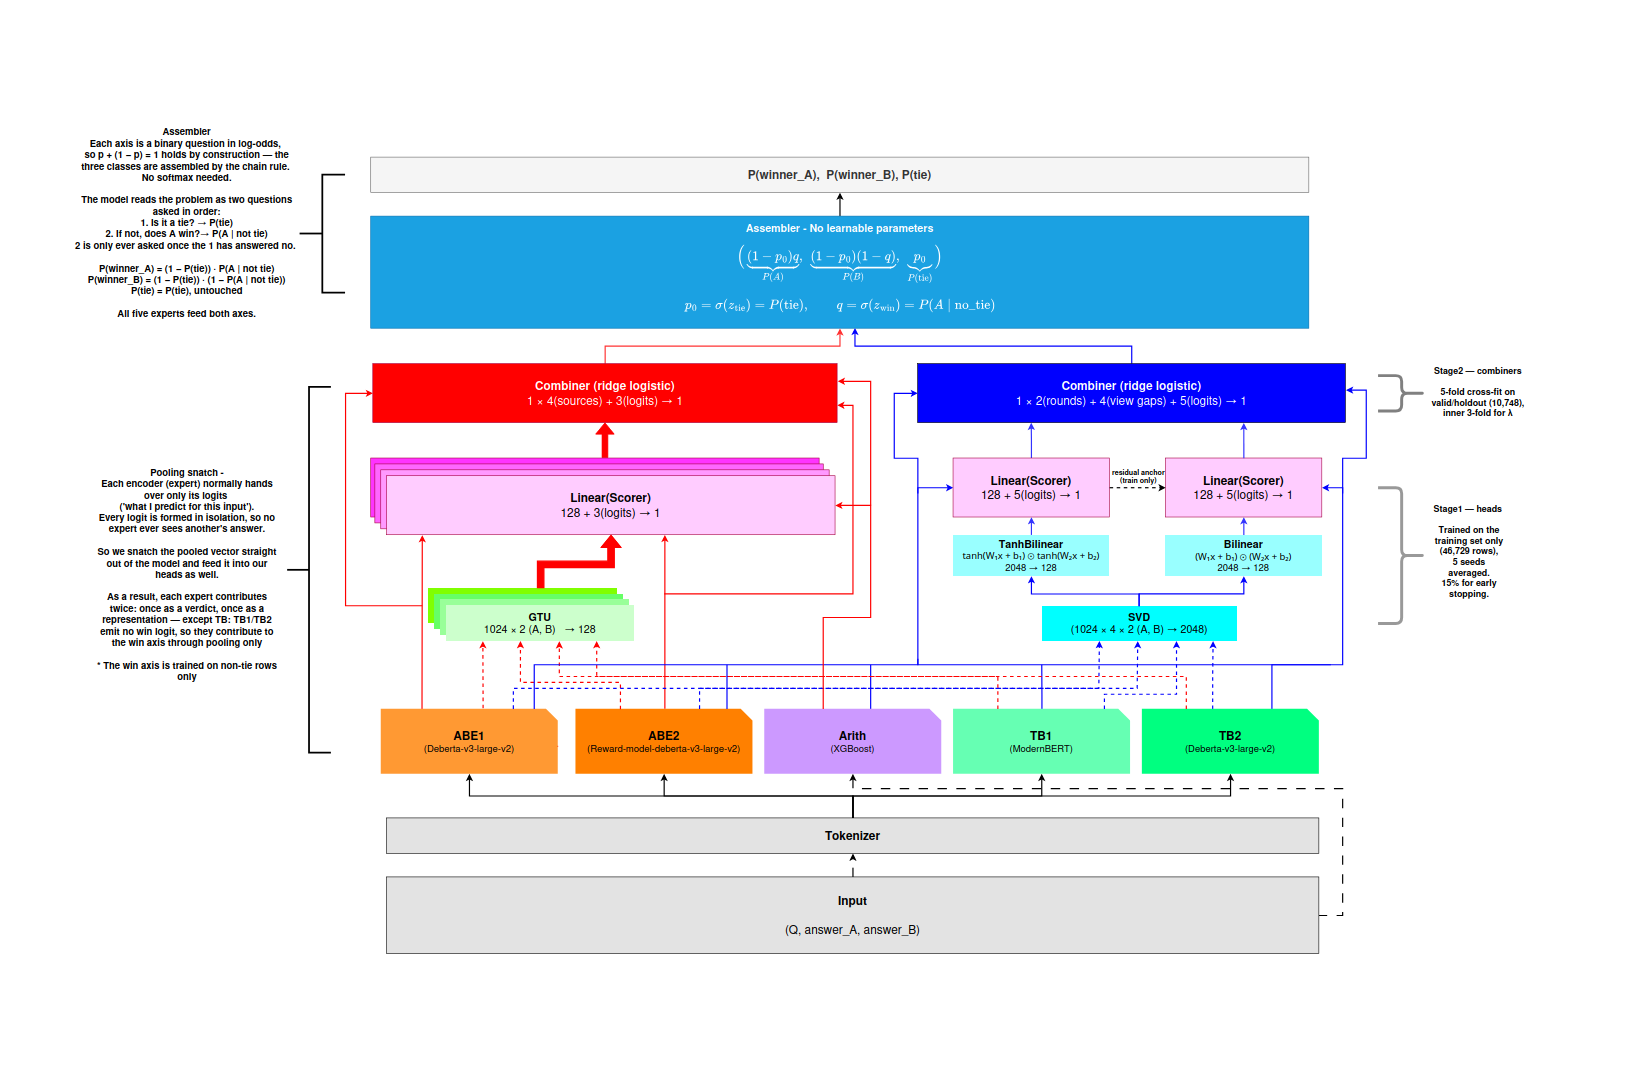

In [2]:
Image("/kaggle/input/datasets/illuminatep/figures/fig1.png", width=1800)

Figure 1 : Overall pipeline. Five experts feed the unified head independently.

### **An agentic system, implemented with encoders**
Without ever seeing another expert's answer, each expert submits its logits (its own verdict) and its pooled vector (the evidence behind it) to the unified head.<br>
The unified head combines those verdicts and their evidence into a single answer.<br>
- ABE(AB Expert) : decides who wins. Reads (Q;&nbsp;&nbsp;Ans_A) and (Q;&nbsp;&nbsp;Ans_B) separately and compares them, producing three probabilities — winner_A, winner_B, winner_tie.<br>
- TB(TieBreaker) : decides whether it is a tie. Reads (Q;&nbsp;&nbsp;Ans_A;&nbsp;&nbsp;Ans_B) in a single pass, producing two probabilities — is_tie, is_no_tie.<br>
- Arith(Arithmetic Expert) : decides by the arithmetic features. Judges 224 arithmetic features drawn from the text (length, structure, relevance to the question, similarity between the answers, and so on) with trees, producing three probabilities.<br>
<br>
The four encoders (ABE1, ABE2, TB1, TB2) submit logits and pooling. Arith (XGBoost) submits logits only.<br><br>
<div style="text-align:left">
<table style="display:inline-table; margin:0 !important">
<thead>
<tr>
<th style="text-align:left">Experts</th>
<th style="text-align:center">Tie axis<br><small>"Is it a tie?"</small></th>
<th style="text-align:center">Win axis<br><small>"If not, does A win?"</small></th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align:left"><b>ABE1 · ABE2</b><br><small>bi-encoder</small></td>
<td style="text-align:center">logits · pooling</td>
<td style="text-align:center">logits · pooling</td>
</tr>
<tr>
<td style="text-align:left"><b>TB1 · TB2</b><br><small>cross-encoder</small></td>
<td style="text-align:center">logits · pooling</td>
<td style="text-align:center">pooling</td>
</tr>
<tr>
<td style="text-align:left"><b>Arith</b><br><small>XGBoost</small></td>
<td style="text-align:center">logits</td>
<td style="text-align:center">logits</td>
</tr>
</tbody>
</table>
</div><br>

The unified head does not solve the 3-class problem all at once.<br> It divides the problem in two and conquers each part (divide and conquer).<br>

1. Tie axis&nbsp; — "Is it a tie?"<br>  

2. Win axis&nbsp; — "If not, does A win?"<br><br>

The two probabilities are then assembled into the final three.

Let $p = P(\text{tie})$,&nbsp;&nbsp;$q = P(A \mid \text{no\_tie})$. Then <br>
$\bigl(P(A),\,P(B),\,P(\text{tie})\bigr) = \bigl((1-p)q,\;(1-p)(1-q),\;p\bigr)$.

<br>
The total loss therefore decomposes exactly into (tie-axis logloss) + (no_tie fraction) × (win-axis logloss).<br>

<hr>

### **인코더로 에이전틱 시스템을 구현한다.**
각 전문가는 서로의 답을 보지 못한 채 각자 로짓(본인 판단)과 풀링(판단의 근거)을 통합 헤드에 제출한다.<br>
통합 헤드는 그 판단과 근거를 종합해 하나의 답을 낸다.<br>
- ABE : 승부 전문가, (Q;&nbsp;&nbsp;Ans_A), (Q;&nbsp;&nbsp;Ans_B)를 각각 읽은 후 비교해서 winner_A, winner_B, winner_tie의 3가지 확률을 산출한다.<br>
- TB : 무승부 전문가, (Q;&nbsp;&nbsp;Ans_A;&nbsp;&nbsp;Ans_B)를 한 번에 읽어서 is_tie, is_no_tie의 2가지 확률을 산출한다.<br>
- Arith : 산술 전문가, 텍스트에서 뽑은 224개의 산술 특성(길이·구조·질문 관련성·응답 간 유사도 등)을 트리로 판정해 3가지 확률을 산출한다.<br>
<br>
4개의 인코더(ABE1, ABE2, TB1, TB2)는 로짓과 풀링을, Arith(XGBoost)는 로짓만 제출한다.<br><br>
<div style="text-align:left">
<table style="display:inline-table; margin:0 !important">
<thead>
<tr>
<th style="text-align:left">전문가</th>
<th style="text-align:center">무승부축<br><small>"무승부인가?"</small></th>
<th style="text-align:center">승부축<br><small>"아니라면 A가 이기는가?"</small></th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align:left"><b>ABE1 · ABE2</b><br><small>bi-encoder</small></td>
<td style="text-align:center">로짓 · 풀링</td>
<td style="text-align:center">로짓 · 풀링</td>
</tr>
<tr>
<td style="text-align:left"><b>TB1 · TB2</b><br><small>cross-encoder</small></td>
<td style="text-align:center">로짓 · 풀링</td>
<td style="text-align:center">풀링</td>
</tr>
<tr>
<td style="text-align:left"><b>Arith</b><br><small>XGBoost</small></td>
<td style="text-align:center">로짓</td>
<td style="text-align:center">로짓</td>
</tr>
</tbody>
</table>
</div><br>

통합 헤드는 3-class 문제를 한 번에 풀지 않고 두 개의 문제로 나누어 분할 정복(divide and conquer)한다.<br>

1. 무승부축  — "무승부인가?"<br>  

2. 승부축  — "무승부가 아니면 A가 이기는가?"<br><br>

이후 두 확률을 조립해 최종 확률을 도출한다.

$p = P(\text{tie})$,&nbsp;&nbsp;$q = P(A \mid \text{no\_tie})$라 하면, <br>
$\bigl(P(A),\,P(B),\,P(\text{tie})\bigr) = \bigl((1-p)q,\;(1-p)(1-q),\;p\bigr)$이다.

<br>
따라서 총 손실은 (무승부축 logloss) + (no_tie 비율) × (승부축 logloss)로 정확히 분해된다.<br>

# 1. Import

In [3]:
import os, json, contextlib, time, gc, random, sys, shutil
from pathlib import Path
from tqdm import tqdm

# Turn off all warnings
# 경고 off
import warnings
warnings.filterwarnings('ignore')
from transformers import logging as hf_logging
os.environ['TRANSFORMERS_VERBOSITY'] = 'error'
os.environ['PYTHONWARNINGS'] = 'ignore'
hf_logging.set_verbosity_error()

os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import expit


import torch
import torch.nn as nn
from transformers import AutoConfig, AutoModel
from safetensors.torch import load_file

from sklearn.utils.extmath import randomized_svd
from sklearn.model_selection import StratifiedKFold

In [4]:
# GPU Configuration for kaggle
# GPU 설정(T4 * 2)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('device:', DEVICE)
print('torch version :', torch.__version__)
print('cuda build    :', torch.version.cuda)
print('cuda available:', torch.cuda.is_available())
print('device count  :', torch.cuda.device_count())

if torch.cuda.is_available():
    print('device name   :', torch.cuda.get_device_name(0))
    print('capability    :', torch.cuda.get_device_capability(0))
    # Cuda test
    # Cuda 연산 테스트
    try:
        x = torch.zeros(3, device='cuda')
        y = x + 1
        print('GPU calculation is available', y.tolist())
    except Exception as e:
        print('GPU calculation is unavailable', e)
else:
    print('No Cuda detected!')

device: cuda
torch version : 2.11.0+cu128
cuda build    : 12.8
cuda available: True
device count  : 2
device name   : Tesla T4
capability    : (7, 5)
GPU calculation is available [1.0, 1.0, 1.0]


### Flag : False when training heads, True when submission

In [5]:
# 통합 헤드 학습 = False, 제출 = True
SUBMIT = True

### Directory setup

In [6]:
# 경로 설정
if Path('/kaggle/input').exists():
    # when Kaggle
    ROOT_DIR = Path('/kaggle/working')
    SOURCE_DIR = Path('/kaggle/input/datasets/illuminatep/apfte-bundle-v2')        # Kaggle 입력 Dataset 루트 / input root on Kaggle
    COMP_DIR = Path('/kaggle/input/competitions/llm-classification-finetuning')   # 대회 데이터 / hidden dataset on Kaggle
    print('Environment : Kaggle')
else: 
    # when local
    ROOT_DIR = Path('./')
    SOURCE_DIR = Path('./bundle')   # the bundle folder next to this notebook / 노트북 옆 번들 폴더
    COMP_DIR = Path('./hidden') # Locally mocked hidden.csv — test.csv is holdout.csv renamed (idempotency check) / test.csv = holdout.csv 이름만 바꿈(멱등성 확인)
    print('Environment : local')

# Dataset dir
DATASET_DIR = SOURCE_DIR / 'origin'
MODEL_DIR   = SOURCE_DIR / 'models'

# Output dir
OUTPUT_DIR     = ROOT_DIR / 'outputs'                            
OUTPUT_DIR.mkdir(exist_ok=True)

# Head dir
HEADS_DIR = OUTPUT_DIR / 'heads'
HEADS_DIR.mkdir(parents=True, exist_ok=True)

# Copy .npz files to a writable directory / 쓰기 가능한 디렉터리로 .npz 파일 복사
for _src in (SOURCE_DIR / 'outputs').rglob('*.npz'):           
    _dst = OUTPUT_DIR / _src.relative_to(SOURCE_DIR / 'outputs')
    if not _dst.exists():
        _dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(_src, _dst)
        
# Register arith location / arith 모듈 위치 등록
if str(MODEL_DIR / 'ARITH') not in sys.path:
    sys.path.insert(0, str(MODEL_DIR / 'ARITH'))
import arith

print(f'Mode: {"SUBMISSION" if SUBMIT else "TRAINING"}')
print(f'ROOT_DIR = {ROOT_DIR}')
print(f'SOURCE_DIR = {SOURCE_DIR}')
print(f'COMP_DIR = {COMP_DIR}')
print(f'DATASET_DIR = {DATASET_DIR}')
print(f'MODEL_DIR = {MODEL_DIR}')
print(f'OUTPUT_DIR = {OUTPUT_DIR}')
print(f'HEADS_DIR = {HEADS_DIR}')

Environment : Kaggle
Mode: SUBMISSION
ROOT_DIR = /kaggle/working
SOURCE_DIR = /kaggle/input/datasets/illuminatep/apfte-bundle-v2
COMP_DIR = /kaggle/input/competitions/llm-classification-finetuning
DATASET_DIR = /kaggle/input/datasets/illuminatep/apfte-bundle-v2/origin
MODEL_DIR = /kaggle/input/datasets/illuminatep/apfte-bundle-v2/models
OUTPUT_DIR = /kaggle/working/outputs
HEADS_DIR = /kaggle/working/outputs/heads


### Check bundle

In [7]:
# 번들 검사
DEPLOY_NPZ = HEADS_DIR / 'deploy.npz'      # check deploy bundle when submission = true
SPLIT_IDS  = DATASET_DIR / 'split_ids.csv' # which competition row belongs to which split

_bad = []
for _f in ('train.csv', 'test.csv', 'sample_submission.csv'):
    if not (COMP_DIR / _f).exists():
        _bad.append(f'Missing {_f} ({COMP_DIR}) — attach the competition data')

if not SPLIT_IDS.exists():
    _bad.append(f'Missing {SPLIT_IDS.name} ({DATASET_DIR}) — the bundle must carry the split table')

if SUBMIT and not DEPLOY_NPZ.exists():
    _bad.append(f'[SUBMIT] Missing {DEPLOY_NPZ.name} — run once with SUBMIT=False to build the bundle')

assert not _bad, 'Asset check failed!!:\n  ' + '\n  '.join(_bad)
print('*** Asset check passed ***')

*** Asset check passed ***


### Set seed

In [8]:
# It must be 42, since it is the ultimate answer to life, the universe and everything
SEED = 42                   # stage 2 — fixed: layer-2 folds and the deploy bundle / stage2 — 고정: 층 2 fold · 배포 번들
SEEDS = (42, 1, 2, 3, 4)    # stage 1 — one layer-1 fit per seed, columns averaged / stage1 — 시드마다 층 1 을 적합해 열을 평균
def set_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    print(f'Seed = {seed}')

set_seeds(SEED)
print(f'Layer-1 seeds = {SEEDS}')

Seed = 42
Layer-1 seeds = (42, 1, 2, 3, 4)


# 2. Load the split dataset / 데이터셋 불러오기

stage 1 = the 46,729 rows the five experts used as their train set<br>
stage 2 = the 5,000 rows that served as the four encoders' valid set (early stopping, checkpoint selection) + a holdout of 5,748 rows nothing has ever seen
- stage 2 fixed — no expert has trained on any of these 10,748 rows.<br><br>

The unified head uses the two stages differently at each layer.
- stage 1 — the layer-1 heads (one per seed), the SVD-1024 basis and the normalization statistics are fitted here and nowhere else. The experts already trained on these rows, so the logits and pooling they produce here are in-sample.<br>
- stage 2 — the layer-2 combiner is cross-fit 5-fold, the tie axis over all 10,748 rows and the win axis over the non-tie ones among them.<br>
- holdout — the final score is read on these 5,748 rows alone.<br>

<hr>

stage 1 = 다섯 전문가가 train set으로 사용한 데이터 46,729행<br>
stage 2 = 네 인코더의 valid set으로 사용한 데이터(ES · 체크포인트 선택 기준) 5,000행 + 한 번도 못 본 holdout 5,748행
- stage 2 fixed — 10,748행 모두 어느 전문가의 학습에도 쓰이지 않았다.<br><br>

통합 헤드는 두 stage 를 층마다 다르게 사용한다.
- stage 1 — 층 1 헤드(시드마다 한 벌), SVD-1024 기저, 정규화 통계를 여기서만 적합한다. 전문가가 이미 학습한 행이라 여기서 나오는 로짓·풀링은 in-sample 이다.<br>
- stage 2 — 층 2 결합기는 무승부축이 10,748행 전체에서, 승부축이 그중 비-tie 행에서 5-fold cross-fit 된다.<br>
- holdout — 최종 점수는 이 5,748행에서만 읽는다.<br>

In [9]:
# The three splits are subsets of the competition's own train.csv, rebuilt here from an id table
# 저장된 id table로 split dataset 복원
comp  = pd.read_csv(COMP_DIR / 'train.csv')
split = pd.read_csv(SPLIT_IDS)

assert split['id'].isin(comp['id']).all(), f'{int((~split["id"].isin(comp["id"])).sum())} split ids are not in the competition train.csv!!'

d = split.merge(comp, on='id', how='left')                 # left merge keeps the table order / 표 순서 유지

train_df   = d[d['split'] == 'train'].drop(columns='split').reset_index(drop=True)      # 46,729 rows
valid_df   = d[d['split'] == 'valid'].drop(columns='split').reset_index(drop=True)      # 5,000 rows — stage2 fixed
holdout_df = d[d['split'] == 'holdout'].drop(columns='split').reset_index(drop=True)    # 5,748 rows

del comp, split, d
_ = gc.collect()

# Stage2 = valid + holdout 
s2_ids = set(valid_df['id']) | set(holdout_df['id'])

# Dataset sanity check / 데이터셋 정합성 검사
assert len(train_df) == 46729, f'train {len(train_df)} != 46,729'
assert len(valid_df) == 5000, f'valid {len(valid_df)} != 5,000'
assert len(holdout_df) == 5748, f'holdout {len(holdout_df)} != 5,748'

for nm, d in (('train', train_df), ('valid', valid_df), ('holdout', holdout_df)):
    assert d['id'].is_unique, f'{nm} id is duplicated!!'

# stage1 과 stage2 는 겹치면 안 된다 / Stage1 and stage2 must not be overlapped
assert not (set(train_df['id']) & s2_ids), 'Overlapping ids detected!!'

# stage2 내 검사 / Validate valid ∩ holdout = ∅
assert not (set(valid_df['id']) & set(holdout_df['id'])), 'valid and holdout overlap!!'

print('*** Dataset split validation passed! ***')
print(f'stage1 = train {len(train_df):,} rows')
print(f'stage2 = valid {len(valid_df):,} + holdout {len(holdout_df):,} = {len(valid_df) + len(holdout_df):,} rows')

*** Dataset split validation passed! ***
stage1 = train 46,729 rows
stage2 = valid 5,000 + holdout 5,748 = 10,748 rows


# 3. preprocessing dataset

In [10]:
# 데이터셋 전처리
for d in (train_df, valid_df, holdout_df):
    # 정수 인코딩
    # Preprocessing Dataset, Integer label encoding: 0 = A wins, 1 = B wins, 2 = tie
    d['label'] = np.select(
        [d['winner_model_a'] == 1,
         d['winner_model_b'] == 1,
         d['winner_tie'] == 1],
        [0, 1, 2],
        default= -1,  # reserved for invalid or missing labels
    )

### Label sanity check

In [11]:
# 라벨 정합성 검사
for name, d in zip(('train','valid','holdout'), (train_df, valid_df, holdout_df)):
    target_cols = ['winner_model_a', 'winner_model_b', 'winner_tie']
     
    # Ensure no rows fall back / 매핑 안 된 행(-1) 없나
    assert (d['label'] != -1).all(), 'There are invalid or missing labels here!'
    
    # Ensure every row is one of these : (1, 0, 0), (0, 1, 0), (0, 0, 1)
    # 모든 행은 (1, 0, 0), (0, 1, 0), (0, 0, 1) 중 하나여야 한다.
    row_sum = d[target_cols].sum(axis=1)
    assert (row_sum == 1).all(), f'There are {int((row_sum != 1).sum())} invalid rows!'
    
    print('*** Label validation passed! ***')
    print(f"Label distribution for {name}: {d['label'].value_counts().sort_index().to_dict()}", end = "")
    
    p = d['label'].value_counts(normalize=True).sort_index() * 100
    print(f"(a={p[0]:.2f}%, b={p[1]:.2f}%, tie={p[2]:.2f}%) \n")

*** Label validation passed! ***
Label distribution for train: {0: 16312, 1: 15977, 2: 14440}(a=34.91%, b=34.19%, tie=30.90%) 

*** Label validation passed! ***
Label distribution for valid: {0: 1745, 1: 1710, 2: 1545}(a=34.90%, b=34.20%, tie=30.90%) 

*** Label validation passed! ***
Label distribution for holdout: {0: 2007, 1: 1965, 2: 1776}(a=34.92%, b=34.19%, tie=30.90%) 



### Build stage 2 df after preprocessing

In [12]:
# stage2(valid + holdout) 생성 — ridge logistic에 사용
stage2_df = pd.concat([valid_df, holdout_df], ignore_index=True)
assert len(stage2_df) == 10748, f'stage2 is invalid!!'

# 4. Define models

### Define Specs

In [13]:
# 모델 스펙 정의
# Checkpoint contract per expert
SPECS = {
    'abe1': dict(arch='abe1',    n_class=3, max_len=2048, q_floor=256, br=True,  backbone='deberta',
                 step=4380, root=MODEL_DIR / 'ABE1', cfg=MODEL_DIR / 'ABE1' / 'config.json',  ckpt=MODEL_DIR / 'ABE1' / 'checkpoint-4380',
                 pool_a=('ea',), pool_b=('eb',)),        # DeBERTa-v3 bi-encoder
    'abe2': dict(arch='abe2',    n_class=3, max_len=2048, q_floor=256, br=True,  backbone='deberta',
                 step=3000, root=MODEL_DIR / 'ABE2',  cfg=MODEL_DIR / 'ABE2' / 'config.json', ckpt=MODEL_DIR / 'ABE2' / 'checkpoint-3000',
                 pool_a=('ea',), pool_b=('eb',)),        # DeBERTa-rm bi-encoder
    'tb1':  dict(arch='tb1', n_class=2, max_len=4096, q_floor=256, br=False, backbone='modernbert',
                 step=5000, root=MODEL_DIR / 'TB1',  cfg=MODEL_DIR / 'TB1' / 'config.json',  ckpt=MODEL_DIR / 'TB1' / 'checkpoint-5000',
                 pool_a=('x_f',), pool_b=('x_s',)),        # ModernBERT cross-encoder
    'tb2':  dict(arch='tb2',  n_class=2, max_len=3072, q_floor=256, br=True,  backbone='deberta',
                 step=4000, root=MODEL_DIR / 'TB2',  cfg=MODEL_DIR / 'TB2' / 'config.json', ckpt=MODEL_DIR / 'TB2' / 'checkpoint-4000',
                 pool_a=('a_f', 'b_s'), pool_b=('b_f', 'a_s'))  # DeBERTa-v3 cross-encoder
}

# Arithmetic Expert. XGBoost model(no forward pass).
ARITH_SPEC = dict(arch='arith', n_class=3, backbone='xgb', family='ab224',
                  n_feat=224, n_folds=5, seed=42,
                  pkg=MODEL_DIR / 'ARITH',
                  cfg=MODEL_DIR / 'ARITH' / 'checkpoint-ab224' / 'meta.json',  
                  ckpt=MODEL_DIR / 'ARITH' / 'checkpoint-ab224',                
                  catalog=MODEL_DIR / 'ARITH' / 'feature_catalog_ab224.csv',  
                  emb=MODEL_DIR / 'ARITH' / 'emb_model',                    # MiniLM local weights
                 )

### Model path validation

In [14]:
# 지정한 경로에 모델 가중치가 있는지 확인
_bad = []

for _tag, _s in list(SPECS.items()) + [('arith', ARITH_SPEC)]:
    # Validate all path actually exists.
    for _k, _v in _s.items():
        if isinstance(_v, Path) and not _v.exists():
            _bad.append(f'[{_tag}] Missing {_k}: {_v}')
            
    if _tag == 'arith':
        # Arith
        for _f in ('meta.json', 'artifacts/tfidf.joblib', 'artifacts/svd.joblib'):
            if not (_s['ckpt'] / _f).exists():
                _bad.append(f'[{_tag}] Missing {_s["ckpt"].name}/{_f}')
                
        for _k in range(1, _s['n_folds'] + 1):
            if not (_s['ckpt'] / f'xgb_fold{_k}.json').exists():
                _bad.append(f'[{_tag}] Missing xgb_fold{_k}.json')
        if not (_s['pkg'] / 'arith' / '__init__.py').exists():
            _bad.append(f'[{_tag}] Missing package: arith/__init__.py')
    else:
        # Each Experts
        for _f in ('config.json', 'tokenizer.json'):
            if not (_s['root'] / _f).exists():
                _bad.append(f'[{_tag}] Missing root/{_f}')
        
        if not (_s['ckpt'] / 'model.safetensors').exists():
            _bad.append(f'[{_tag}] Missing {_s["ckpt"].name}/model.safetensors')

assert not _bad, 'Path validation failed!!:\n  ' + '\n  '.join(_bad)
print('*** Path validation passed! ***')

*** Path validation passed! ***


### Model methods

In [15]:
# Attention pooling
class AttnPool(nn.Module):
    def __init__(self, h):
        super().__init__()
        self.score = nn.Linear(h, 1)

    def forward(self, last_hidden, mask):
        s = self.score(last_hidden).squeeze(-1)
        s = s.float().masked_fill(mask == 0, float('-inf'))
        w = torch.softmax(s, dim=1)
        # empty response -> NaN. map to a zero vector instead of poisoning the batch
        # 빈 응답이 존재하면 softmax 가서 터지니 0으로 대체
        w = torch.nan_to_num(w).unsqueeze(-1)
        return (last_hidden.float() * w).sum(dim=1)

# Build an expert / 전문가 조립
def build_model(tag, ckpt_dir=None):
    spec = SPECS[tag]
    ckpt_dir = Path(ckpt_dir) if ckpt_dir is not None else spec['ckpt']
    config = AutoConfig.from_pretrained(spec['cfg'], local_files_only=True)
    
    if spec['backbone'] == 'deberta':
        enc = AutoModel.from_config(config)
    elif spec['backbone'] == 'modernbert':
        config.reference_compile = False   # Disabled due to ModernBERT compile error
        enc = AutoModel.from_config(config)
    else:
        raise ValueError(f"*** Unknown backbone detected!! : {spec['backbone']}***")
    h = config.hidden_size                 # sets the dimension for all heads below / 아래 모든 헤드의 폭
    
    # for ABE1
    if spec['arch'] == 'abe1':               
        class M(nn.Module):
            def __init__(self):
                super().__init__()
                self.encoder = enc
                self.pool = AttnPool(h)
                self.LN = nn.Identity()  # keeps abe_pooled shared
                self.head = nn.Sequential(nn.LayerNorm(h * 3), nn.Dropout(0.1),
                                          nn.Linear(h * 3, 1024), nn.GELU(),
                                          nn.Dropout(0.1), nn.Linear(1024, 3))
                
    # for ABE2
    elif spec['arch'] == 'abe2':                      
        class M(nn.Module):
            def __init__(self):
                super().__init__()
                self.encoder = enc
                self.pool = AttnPool(h)
                self.LN = nn.LayerNorm(h)
                self.head = nn.Sequential(nn.Dropout(0.1), nn.Linear(h * 4, 1024), nn.GELU(),
                                          nn.Dropout(0.1), nn.Linear(1024, 3))

    # for TB1
    elif spec['arch'] == 'tb1':                                       
        class M(nn.Module):
            def __init__(self):
                super().__init__()
                self.encoder = enc
                self.pool = AttnPool(h)
                self.head = nn.Sequential(nn.Dropout(0.1), nn.Linear(h, h), nn.GELU(),
                                          nn.Dropout(0.1), nn.Linear(h, 2))
                
    # for TB2            
    elif spec['arch'] == 'tb2':                
        class M(nn.Module):
            def __init__(self):
                super().__init__()
                self.encoder = enc
                self.pool_ab = AttnPool(h)
                self.pool_q = AttnPool(h)
                self.LN = nn.LayerNorm(h)
                self.head = nn.Sequential(nn.Dropout(0.1), nn.Linear(h * 5, 1024), nn.GELU(),
                                          nn.Dropout(0.1), nn.Linear(1024, 2))
    else:    
        raise ValueError(f"*** Unknown arch detected!! : {spec['arch']}***")
        
    model = M()
    sd = load_file(ckpt_dir / 'model.safetensors')
    
    missing, unexpected = model.load_state_dict(sd, strict=False)
    assert not missing, f'{tag}: {len(missing)} missing key(s) : {missing[:4]}'
    assert not unexpected, f'{tag}: {len(unexpected)} unexpected key(s) : {unexpected[:4]}'
    
    print(f"*** {spec['arch']} loaded successfully. ***")
    return model.to(DEVICE).eval(), h

### ABE(AB Expert) — 1, 2

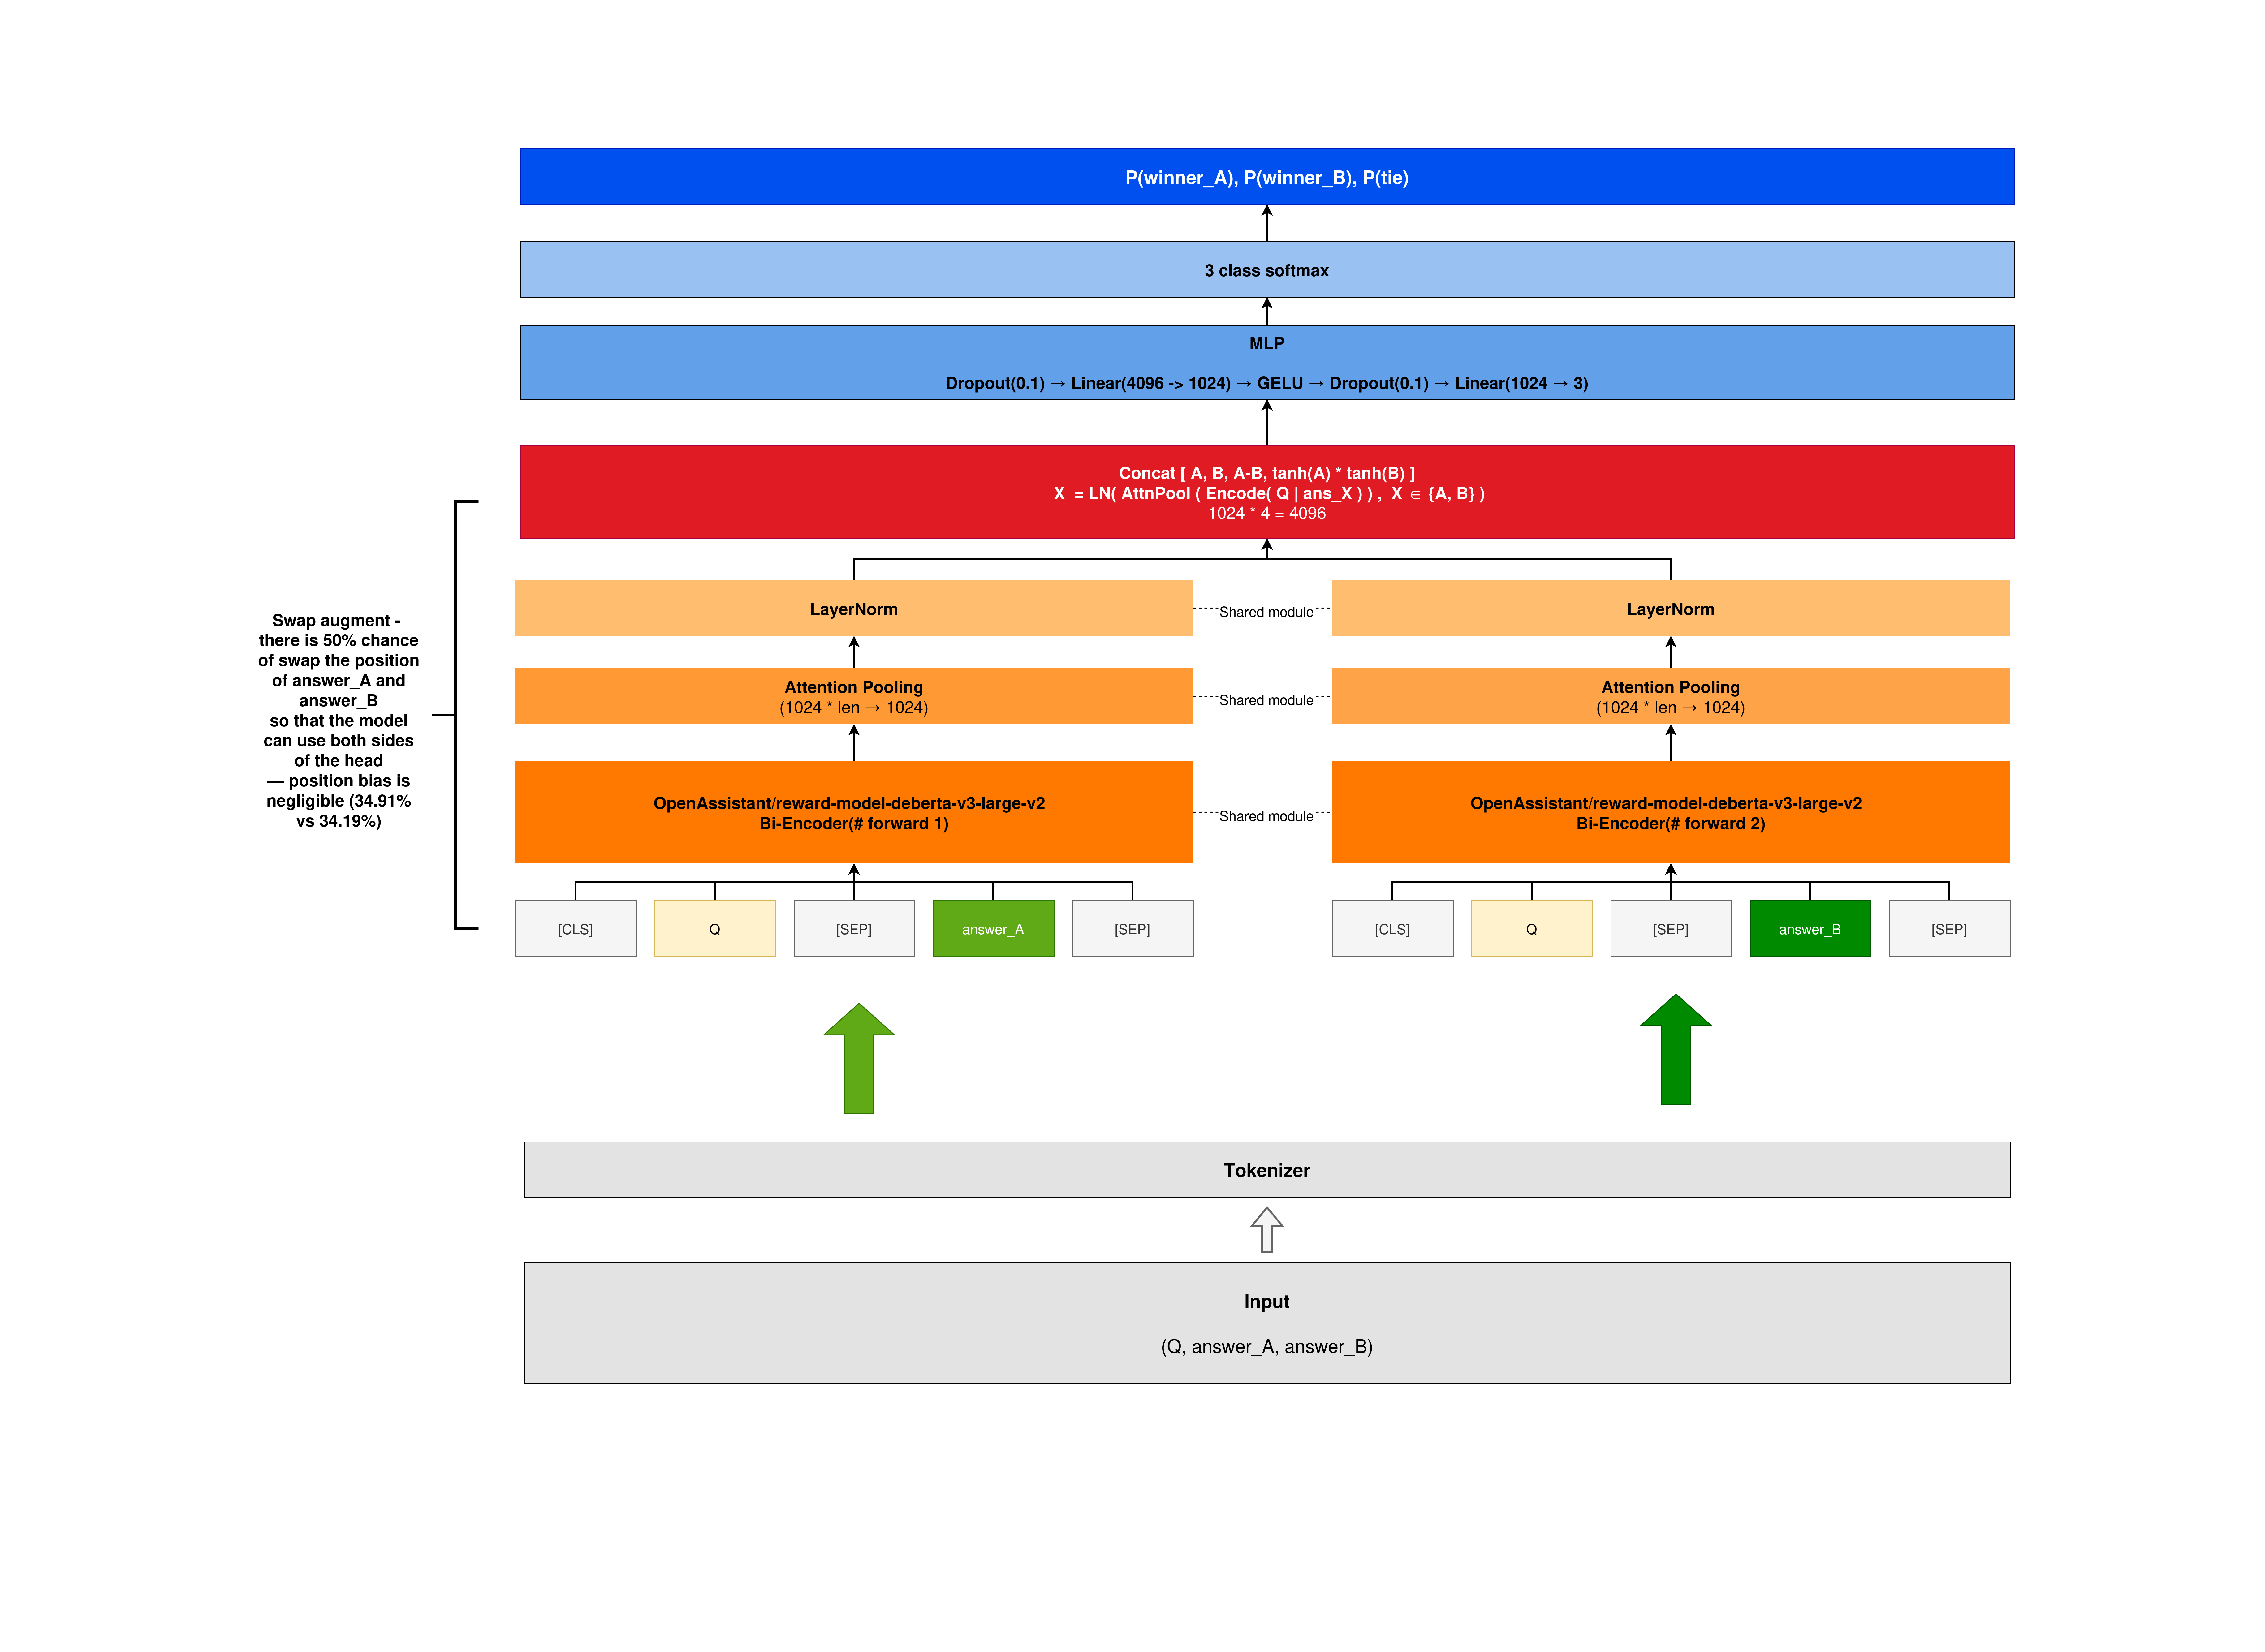

In [16]:
Image("/kaggle/input/datasets/illuminatep/figures/fig2.png", width=1800)

Figure 2: ABE2, a bi-encoder based on `reward-model-deberta-v3-large-v2`.

Fine-tuned from `reward-model-deberta-v3-large-v2`, this is a bi-encoder that reads the two responses separately.<br>

`(Q; Ans_A)` and `(Q; Ans_B)` are tokenized and encoded on their own, attention pooling reduces each to a 1,024-dim `ea` and `eb`, and an MLP head turns them into three logits — newlines are preserved as a `[BR]` token, and the question is guaranteed at least `q_floor=256` tokens of the `max_seq_len=2048` budget.<br>

`ea` and `eb` are submitted to the unified head together with the logits, as the evidence behind the verdict.<br>

Only `ea` and `eb` change places and pass through the head once more, and the two views are then averaged. Every response is scored once in slot A and once in slot B, so whatever depends on the slot cancels out, and training and inference share the same symmetry.<br><br>
ABE1 starts from `DeBERTa-v3-large` and feeds only three blocks [`ea`, `eb`, `ea−eb`] into the head, applying LayerNorm at the head input rather than right after pooling.<br>
The two begin with different prior knowledge and a different structure, so what one misses the other can see.

<hr>

`reward-model-deberta-v3-large-v2` 에서 출발해 두 응답을 따로 읽는 bi-encoder이다.<br>

`(Q; Ans_A)` 와 `(Q; Ans_B)` 를 각각 토크나이즈해 각자 인코딩한 뒤, attention pooling으로 1,024차원 `ea`, `eb` 를 얻고, MLP 헤드에 넣어 3-class 로짓을 산출한다 — 개행은 `[BR]` 로 치환해 보존하고, `max_seq_len=2048` 중 질문에 최소 `q_floor=256` 토큰을 보장한다.<br>

`ea`, `eb` 는 판단의 근거로서 로짓과 함께 통합 헤드에 제출된다.<br>

`ea`, `eb`의 자리만 맞바꿔 한 번 더 헤드에 통과시킨 뒤 평균한다. 모든 응답이 A자리와 B자리에서 한 번씩 채점되므로, 자리에 따라 갈리는 성분이 상쇄되고 학습과 추론이 같은 대칭 구조를 공유한다.<br><br>
ABE1은 `DeBERTa-v3-large` 에서 출발해 헤드에 [`ea`, `eb`, `ea−eb`] 세 블록만 넣고, LayerNorm을 풀링 직후가 아니라 헤드 입력에 건다.<br>
두 모델은 서로 다른 사전지식과 구조에서 출발하므로, 한쪽이 보지 못하는 것을 다른 쪽이 볼 수 있다.

In [17]:
# ABE step 1 — run one branch through encoder -> attention pooling -> LN (called once per side)
@torch.no_grad()
def abe_pooled(model, seqs, PAD, tok_budget, attn_budget, h, desc):
    lengths = np.array([len(s) for s in seqs])
    order = np.argsort(-lengths)
    out = np.zeros((len(seqs), h), np.float32)
    def enc_rows(rows):
        ids, m = pad_batch([seqs[j] for j in rows], PAD)

        def run(amp_on):
            with _amp_ctx(amp_on):
                Hh = model.encoder(input_ids=ids, attention_mask=m).last_hidden_state
                e = model.LN(model.pool(Hh, m))
            return e.float().cpu().numpy()

        return _finite_retry(run, desc)

    bar = tqdm(total=len(seqs), desc=desc, unit='rows', leave=False)
    for idx in batched(order, lengths, tok_budget, attn_budget, True):
        out[idx] = oom_safe(enc_rows, list(idx))
        bar.update(len(idx))
    bar.close()
    return out


# ABE step 2 — pair the two pooled vectors into the head, forward and swapped (swap-TTA)
@torch.no_grad()
def abe_heads(model, ea, eb, arch='abe2'):
    # abe1 head = [ea, eb, ea-eb]
    if arch == 'abe1':
        cat = lambda a, b: torch.cat([a, b, a - b], 1)
    # abe2 head = [ea, eb, ea-eb, tanh(ea) ⊙ tanh(eb)]
    else:
        cat = lambda a, b: torch.cat([a, b, a - b, torch.tanh(a) * torch.tanh(b)], 1)
    zf, zs = [], []
    for st in range(0, len(ea), 8192):
        a = torch.tensor(ea[st:st + 8192], device=DEVICE)
        b = torch.tensor(eb[st:st + 8192], device=DEVICE)
        
        # bind this chunk's tensors
        def run(amp_on, a=a, b=b):
            with _amp_ctx(amp_on):
                f = model.head(cat(a, b))
                s = model.head(cat(b, a))
            return np.hstack([f.float().cpu().numpy(), s.float().cpu().numpy()])

        z = _finite_retry(run, f'{arch} head')
        w = z.shape[1] // 2
        zf.append(z[:, :w])
        zs.append(z[:, w:][:, [1, 0, 2]])
    return np.vstack(zf), np.vstack(zs)

### TB(Tie Expert) — 1, 2

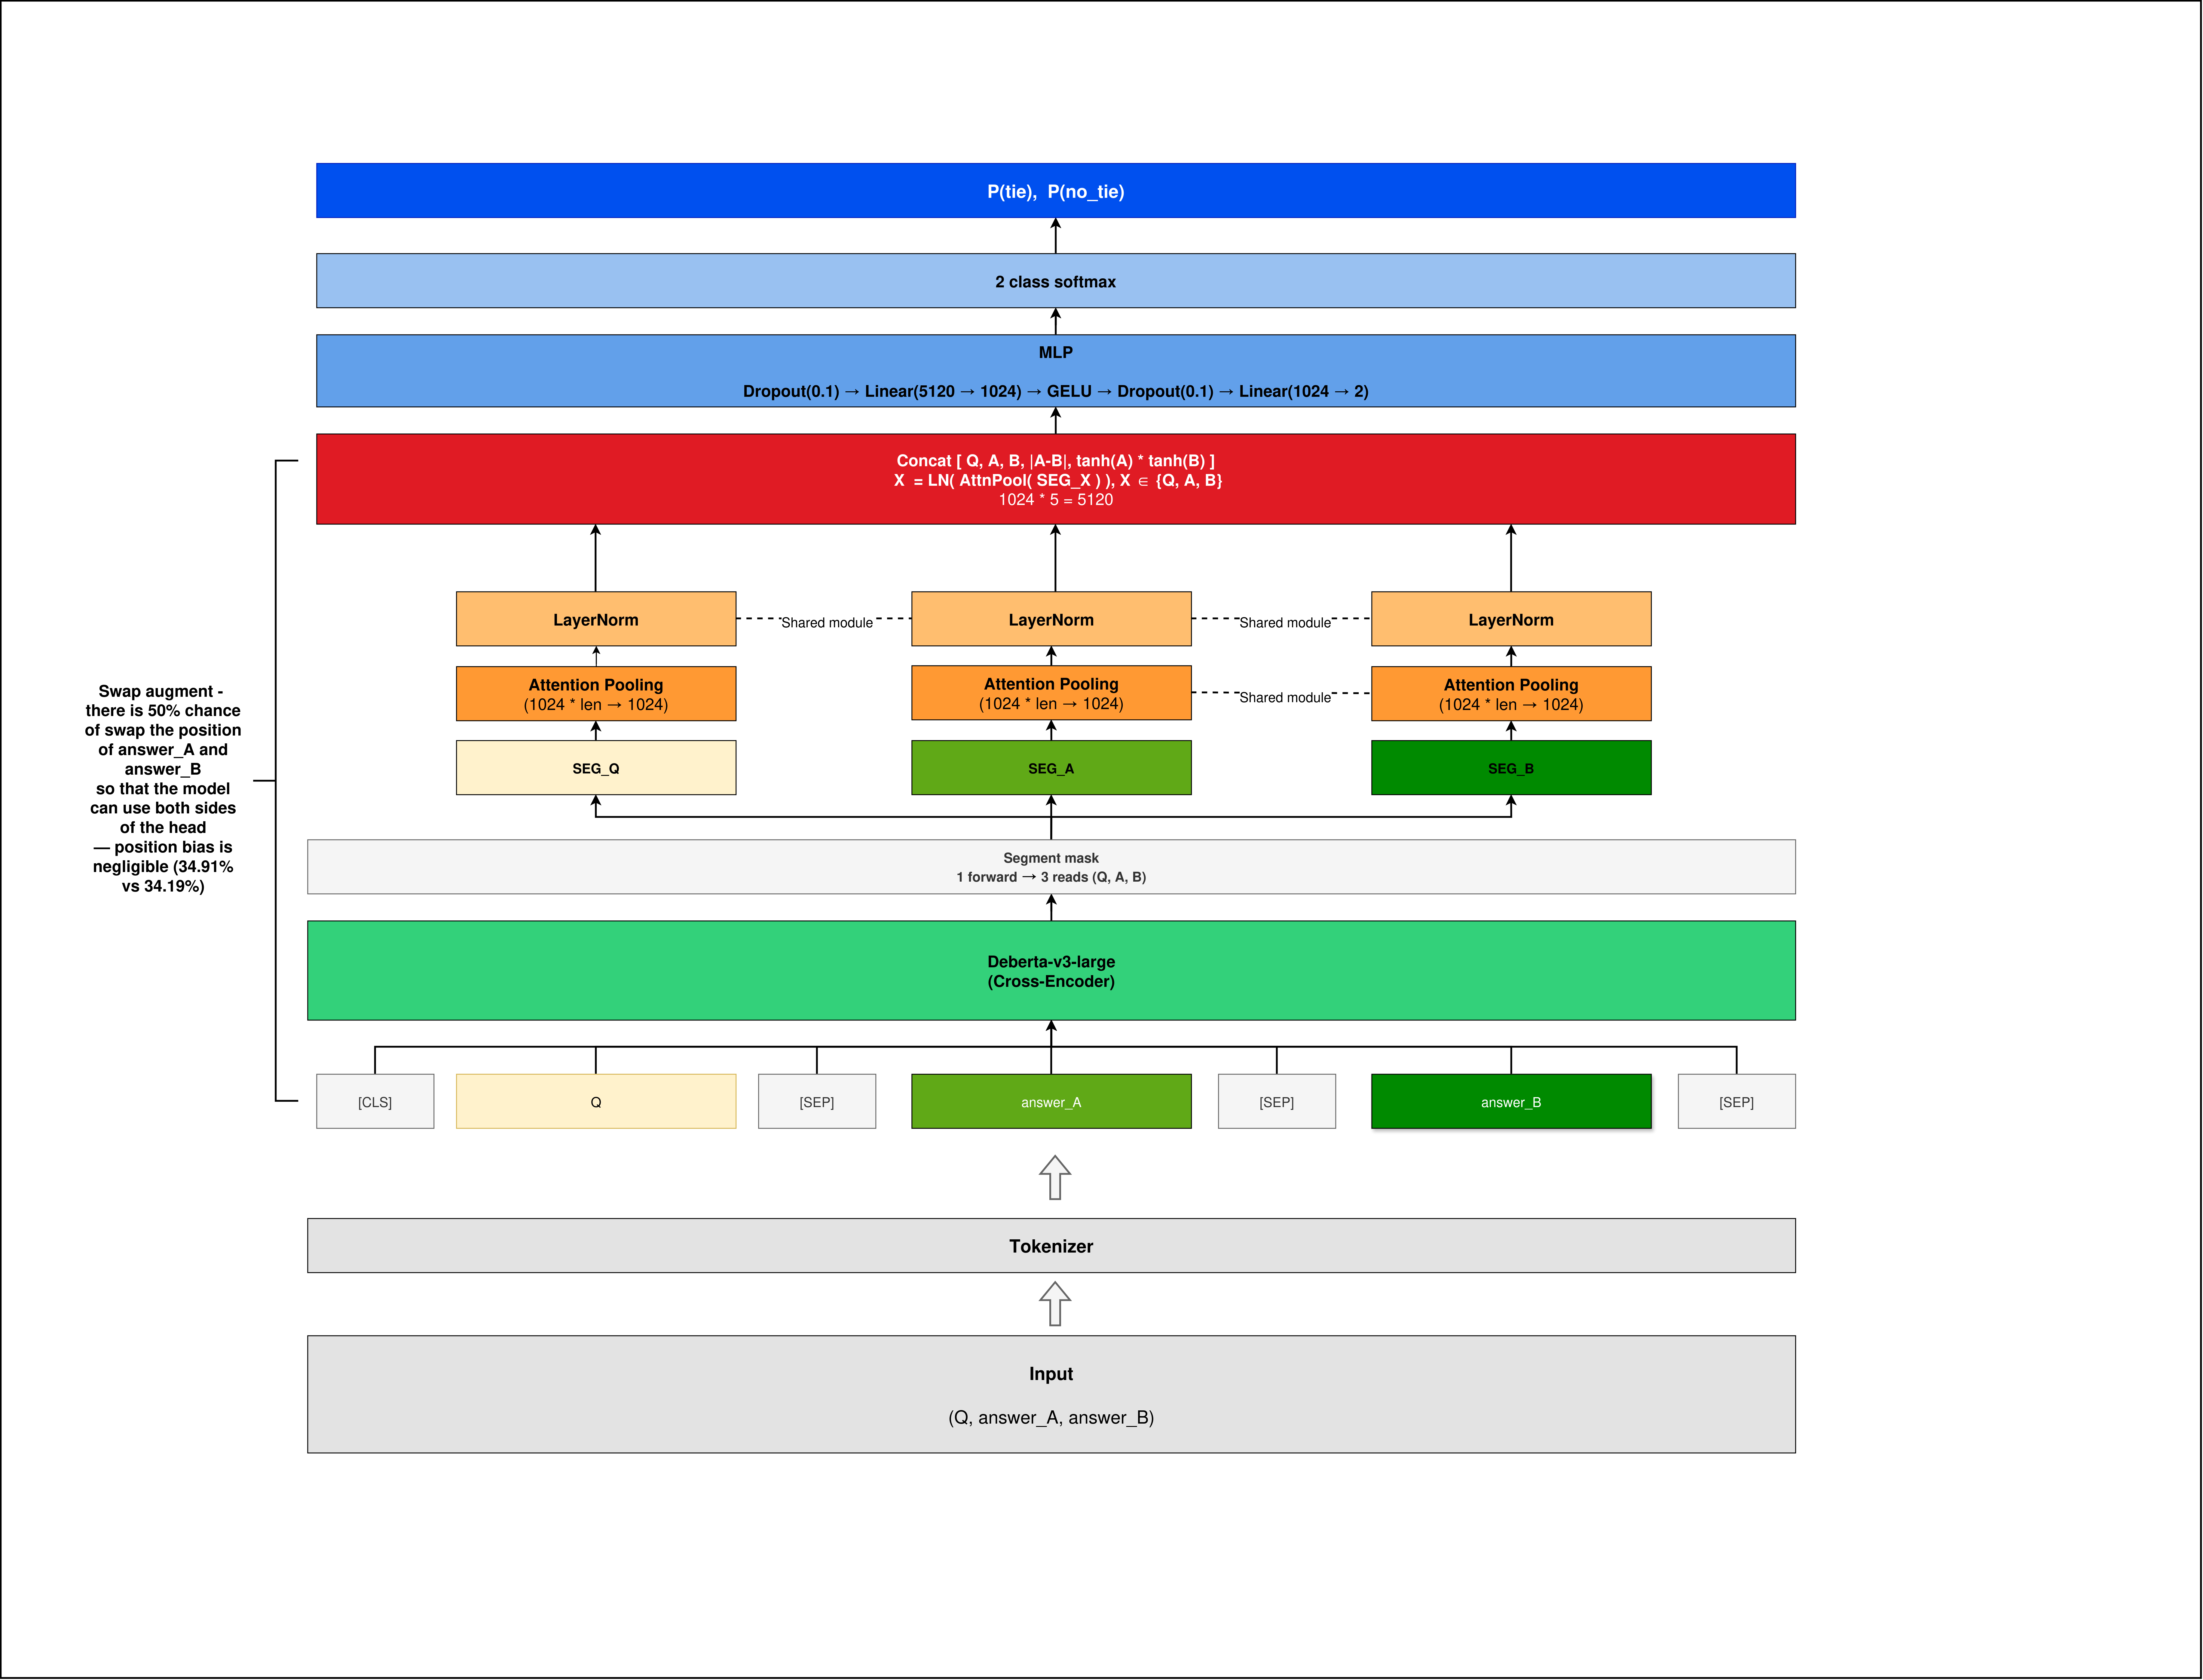

In [18]:
Image("/kaggle/input/datasets/illuminatep/figures/fig3.png", width=1800)

Figure 3: TB2, a cross-encoder based on `deberta-v3-large`.

Fine-tuned from `DeBERTa-v3-large`, this is a cross-encoder that reads the two responses at once.<br>

`(Q; Ans_A; Ans_B)` is tokenized and encoded as a single sequence, segment-wise attention pooling draws a 1,024-dim `eq`, `ea` and `eb` from the question, A and B spans, and an MLP head turns them into two logits — newlines are preserved as a `[BR]` token, and the question is guaranteed at least `q_floor=256` tokens of the `max_seq_len=3072` budget.<br>

`ea` and `eb` are submitted to the unified head together with the logits, as the evidence behind the verdict.<br>

Ans_A and Ans_B change places, the sequence is rebuilt and run once more, and the two views are then averaged. Unlike a bi-encoder, a change of slots changes the sequence itself, so every swapped view costs a full pass through the encoder. Every response is scored once in slot A and once in slot B, so whatever depends on the slot cancels out, and training and inference share the same symmetry.<br><br>
TB1 starts from `ModernBERT` and pools the whole sequence at once, without a `[BR]` token (`max_seq_len=4096`).<br>
The two begin with different prior knowledge and a different structure, so what one misses the other can see.

<hr>

`DeBERTa-v3-large` 에서 출발해 두 응답을 한 번에 읽는 cross-encoder이다.<br>

`(Q; Ans_A; Ans_B)` 를 한 시퀀스로 토크나이즈해 인코딩한 뒤, 구간별 attention pooling으로 질문·A·B 자리에서 1,024차원 `eq`, `ea`, `eb` 를 각각 뽑고, MLP 헤드에 넣어 2-class 로짓을 산출한다 — 개행은 `[BR]` 로 치환해 보존하고, `max_seq_len=3072` 중 질문에 최소 `q_floor=256` 토큰을 보장한다.<br>

`ea`, `eb` 는 판단의 근거로서 로짓과 함께 통합 헤드에 제출된다.<br>

Ans_A/Ans_B의 자리만 맞바꿔 시퀀스를 다시 만들어 한 번 더 돌린 뒤 평균한다. bi-encoder와 달리 자리가 바뀌면 시퀀스 자체가 달라져, 스왑마다 인코더를 통째로 다시 통과시켜야 한다. 모든 응답이 A자리와 B자리에서 한 번씩 채점되므로, 자리에 따라 갈리는 성분이 상쇄되고 학습과 추론이 같은 대칭 구조를 공유한다.<br><br>

TB1은 `ModernBERT` 에서 출발해 `[BR]` 없이 시퀀스 전체를 한 번에 attention pooling 한다(`max_seq_len=4096`).<br>
두 모델은 서로 다른 사전지식과 구조에서 출발하므로, 한쪽이 보지 못하는 것을 다른 쪽이 볼 수 있다.

In [19]:
# TB — encoder and head in one pass.
# TB — 인코더와 헤드를 한 번에.
@torch.no_grad()
def tb_view(model, spec, Q, A, B, CLS, SEP, PAD, tok_budget, attn_budget, desc, sel=None,
            h=None, want_pool=False):
    sel = np.arange(len(Q)) if sel is None else np.asarray(sel)
    seg = spec['arch'] == 'tb2'               # TB2 = segment pooling / TB1 = full span
    quad = spec['backbone'] == 'deberta'      # ModernBERT uses sdpa
    ml, qf = spec['max_len'], spec['q_floor']
    built = {j: build_triple(Q[j], A[j], B[j], CLS, SEP, ml, qf) for j in sel}
    lengths = np.array([len(built[j][0]) for j in sel])
    order = np.argsort(-lengths)
    
    # Logits and pooling travel as one (rows, width) array so oom_safe/batched handle a single block. 
    # TB2: 2 + 3h [logits | q | a | b] (after LN) / TB1: 2 +  h [logits | x]
    # oom_safe/batched 가 (행, 폭) 하나만 다루기 때문에 로짓과 풀링을 한 배열로 내보낸다. 
    W_ = 2 + (0 if not want_pool else (3 * h if seg else h))
    out = np.zeros((len(sel), W_), np.float32)

    def fwd_rows(rows):
        ids, m = pad_batch([built[j][0] for j in rows], PAD)

        def run(amp_on):
            with _amp_ctx(amp_on):
                Hh = model.encoder(input_ids=ids, attention_mask=m).last_hidden_state
                if seg:
                    # One mask per span, so each pool sees only its own tokens
                    # 구간마다 마스크를 따로 세워 각 풀링이 자기 토큰만 보게 한다
                    sm = {}
                    for name, k in (('q', 0), ('a', 1), ('b', 2)):
                        zm = torch.zeros_like(m)
                        for r, j in enumerate(rows):
                            s0, s1 = built[j][1][k]
                            zm[r, s0:s1] = 1
                        sm[name] = zm
                    q = model.LN(model.pool_q(Hh, sm['q']))
                    a = model.LN(model.pool_ab(Hh, sm['a']))
                    b = model.LN(model.pool_ab(Hh, sm['b']))
                    # tb2 head = [eq, ea, eb, |ea-eb|, tanh(ea) ⊙ tanh(eb)]
                    x = torch.cat([q, a, b, (a - b).abs(), torch.tanh(a) * torch.tanh(b)], 1)
                else:
                    # tb1 head = [x] — the whole span pooled once, no LN
                    x = model.pool(Hh, m)
                logits = model.head(x)
            z = logits.float().cpu().numpy()
            if not want_pool:
                return z
            # Only pass q/a/b
            pool = torch.cat([q, a, b], 1) if seg else x
            return np.hstack([z, pool.float().cpu().numpy()])

        return _finite_retry(run, desc)

    bar = tqdm(total=len(sel), desc=desc, unit='rows', leave=False)
    for pos in batched(order, lengths, tok_budget, attn_budget, quad):
        out[pos] = oom_safe(fwd_rows, [sel[p] for p in pos])
        bar.update(len(pos))
    bar.close()
    return out

### Arith

An arithmetic expert that decides winner_A, winner_B and winner_tie from the numbers alone.<br>

224 arithmetic features are drawn from `(Q, Ans_A, Ans_B)` — length and structure statistics, relevance to the question, similarity between the answers, MiniLM embeddings and BERTScore — and a 5-fold XGBoost turns them into three logits.<br>

Unlike the other experts, a tree model has no internal representation just before the answer, so Arith submits logits only.<br>

The feature matrix is transformed as if the slots had traded places, run once more, and the two views are averaged in margin space — difference columns flip sign (55), ratio columns are inverted (1), columns that come in an A and a B version trade values (9 pairs), and the rest are left alone (150).<br>
The catalog records which rule each feature follows, so the text is never read again.<br><br>

On the 5,748 holdout rows Arith alone reaches an uncalibrated 3-class logloss of 0.9966 (tie axis 0.5831, win axis 0.5985).<br>
It sees what the four encoders miss, so the unified head takes its logits on both the tie and the win axis.

<hr>

산술 피쳐만으로 winner_A, winner_B, winner_tie의 3진 분류를 수행하는 산술 전문가이다.<br>

(Q, Ans_A, Ans_B)에서 길이·구조 통계, 질문과의 관련성, 응답 간 유사도, MiniLM 임베딩과 BERTScore 등의 224개 산술 피쳐를 뽑아 XGBoost 5-fold 에 넣어 3-class 로짓을 산출한다.<br>

다른 전문가와 달리 트리 모델이라 답 직전의 내부 표현이 없어 로짓만 제출한다.<br>

피쳐 행렬의 자리를 변환해 한 번 더 통과시킨 뒤 마진 공간에서 평균한다 — 차이 열은 부호를 뒤집고(55), 비율 열은 역수를 취하고(1), A판·B판이 따로 있는 열은 값을 맞바꾸며(9쌍), 나머지는 그대로 둔다(150).<br>
종류가 카탈로그에 적혀 있어 텍스트를 다시 읽지 않는다.<br><br>

단독 성능은 holdout 5,748행에서 무보정 3-class logloss 0.9966다(무승부축 0.5831 · 승부축 0.5985).<br>
4종의 인코더가 못 보는 것을 보므로, 통합 헤드는 무승부축과 승부축 모두에서 이 로짓을 받는다.

In [20]:
# Load arith / Arithmetic expert 적재 
print('*** Loading arithmetic expert ***')
ari = arith.load(ckpt=ARITH_SPEC['ckpt'],
                 catalog=ARITH_SPEC['catalog'],
                 emb=ARITH_SPEC['emb'])
assert len(ari.cols) == ARITH_SPEC['n_feat'], \
    f'{len(ari.cols)} contract columns != declared n_feat {ARITH_SPEC["n_feat"]}'
assert ari.meta['seed'] == 42, 'Invalid seed detected!!'

*** Loading arithmetic expert ***
*** arith checkpoint-ab224 loaded 224 features, 5-fold xgb ***


### Model sanity check

In [21]:
# Load each model, compare with specs and return.
# 각 모델을 하나씩 로드하고, specs와 대조 후 반환한다.
HEAD_IN_MULT = {'abe1': 3, 'abe2': 4, 'tb1': 1, 'tb2': 5}   # head input width 

for _tag, _spec in SPECS.items():
    _model, _h = build_model(_tag)
    _lins = [m for m in _model.head if isinstance(m, nn.Linear)]
    _in, _out = _lins[0].in_features, _lins[-1].out_features
    _n_all = sum(p.numel() for p in _model.parameters())
    _n_enc = sum(p.numel() for p in _model.encoder.parameters())

    assert _in == _h * HEAD_IN_MULT[_spec['arch']], \
        f'{_tag}: head input {_in} != {HEAD_IN_MULT[_spec["arch"]]} x hidden {_h}!!'
    assert _out == _spec['n_class'], f'{_tag}: readout {_out} != declared n_class {_spec["n_class"]}!!'
    assert not _model.training, f'{_tag}: model is not in eval mode!!'
    assert next(_model.parameters()).device.type == DEVICE.type, f'{_tag}: model is not on {DEVICE}!!'

    print(f'  [{_tag}] {type(_model.encoder).__name__:<16} hidden {_h} | '
          f'head {_in} -> {_out} | params {_n_all / 1e6:.1f}M (encoder {_n_enc / 1e6:.1f}M)')

    # Assembly proof only, free it
    del _model, _lins
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()

print(f'*** Assembly check passed ***')

*** abe1 loaded successfully. ***
  [abe1] DebertaV2Model   hidden 1024 | head 3072 -> 3 | params 437.2M (encoder 434.0M)
*** abe2 loaded successfully. ***
  [abe2] DebertaV2Model   hidden 1024 | head 4096 -> 3 | params 438.2M (encoder 434.0M)
*** tb1 loaded successfully. ***
  [tb1] ModernBertModel  hidden 1024 | head 1024 -> 2 | params 395.8M (encoder 394.8M)
*** tb2 loaded successfully. ***
  [tb2] DebertaV2Model   hidden 1024 | head 5120 -> 2 | params 439.3M (encoder 434.0M)
*** Assembly check passed ***


### Extract from each encoder

In [22]:
# 각 인코더 호출 후 로짓, 풀링 추출
def run_model(tag, model, h, tok_state, tok_budget, attn_budget, sel=None, want_pool=False):
    spec = SPECS[tag]
    Q, A, B, CLS, SEP, PAD = tok_state

    if spec['arch'] in ('abe1', 'abe2'):
        # Only the head input and the LN position differ.
        # 두 ABE는 헤드 입력과 LN 위치만 다르다.
        idx = np.arange(len(Q)) if sel is None else np.asarray(sel)
        rows = [abe_build_row(Q[j], A[j], B[j], CLS, SEP, spec['max_len'], spec['q_floor'])
                for j in idx]
        # bi-encoder — a swap only exchanges ea <-> eb, so the encoder never runs again
        # bi-encoder — 스왑은 ea <-> eb 교환이라 인코더가 다시 돌지 않는다
        ea = abe_pooled(model, [r[0] for r in rows], PAD, tok_budget, attn_budget, h,
                        f'{tag} a-branch')
        eb = abe_pooled(model, [r[1] for r in rows], PAD, tok_budget, attn_budget, h,
                        f'{tag} b-branch')
        f_, s_ = abe_heads(model, ea, eb, arch=spec['arch'])
        return f_, s_, ({'ea': ea, 'eb': eb} if want_pool else None)

    # cross-encoder — the swapped view is a different sequence, so the encoder runs twice.
    # cross-encoder — 스왑 뷰는 다른 시퀀스라 인코더가 두 번 돈다.
    kw = dict(h=h, want_pool=want_pool)
    fwd = tb_view(model, spec, Q, A, B, CLS, SEP, PAD, tok_budget, attn_budget,
                  f'{tag} fwd', sel, **kw)
    swp = tb_view(model, spec, Q, B, A, CLS, SEP, PAD, tok_budget, attn_budget,
                  f'{tag} swp', sel, **kw)
    if not want_pool:
        return fwd, swp, None

    pf, ps = fwd[:, 2:], swp[:, 2:]
    fwd, swp = fwd[:, :2], swp[:, :2]
    # 
    if spec['arch'] == 'tb2':
        # Segment-named keys — swapped 'a' is response B / 구간 기준 이름 — 스왑의 a 는 응답 B
        pool = {'q_f': pf[:, :h], 'a_f': pf[:, h:2 * h], 'b_f': pf[:, 2 * h:],
                'q_s': ps[:, :h], 'a_s': ps[:, h:2 * h], 'b_s': ps[:, 2 * h:]}
    else:
        pool = {'x_f': pf, 'x_s': ps}
    return fwd, swp, pool

# 5. Tokenizing

### Save context from long sentence

In [23]:
# 긴 문장에서 문맥을 보존하기 위한 헬퍼 함수
HEAD_FRAC = 0.6      # 잘릴 때 앞 60% + 뒤 40% / keep 60% head + 40% tail when truncating
CHAR_CAP = 20000     # 문자 상한 — 토크나이즈 전 1차 절단 / char cap before tokenization

def parse_text(x):
    if pd.isna(x):
        return ''
    try:
        turns = json.loads(x)
    except (json.JSONDecodeError, TypeError):
        return str(x)
    if isinstance(turns, list):
        return ' '.join(t for t in turns if isinstance(t, str))
    return str(turns)


def char_head_tail(s):
    if len(s) <= CHAR_CAP:
        return s
    h = int(CHAR_CAP * HEAD_FRAC)
    return s[:h] + s[-(CHAR_CAP - h):]


def head_tail(ids, k):
    ids = list(ids)
    if len(ids) <= k:
        return ids
    h = int(k * HEAD_FRAC)
    t = k - h
    return ids[:h] + ids[-t:] if t > 0 else ids[:h]

# Q floor first, split the rest between A/B, leftovers go back to Q. / 예산 배분 함수, Q에 최소 예산을 보장하고 A,B가 쓰고 남은 예산은 Q가 회수한다.
def alloc_qab(lq, la, lb, budget, q_floor):
    kq = min(lq, q_floor)
    rem = budget - kq
    half = rem // 2
    if la <= half and lb <= half:
        ka, kb = la, lb
    elif la <= half:
        ka, kb = la, min(lb, rem - la)
    elif lb <= half:
        kb, ka = lb, min(la, rem - lb)
    else:
        ka, kb = half, rem - half
    kq = min(lq, kq + (budget - kq - ka - kb))
    return kq, ka, kb

### build sequence

In [24]:
# Sequence assembler for TB / TB(cross-encoder)용 시퀀스 조립 함수 
def build_triple(iq, ia, ib, CLS, SEP, max_len, q_floor):
    budget = max_len - 4
    kq, ka, kb = alloc_qab(len(iq), len(ia), len(ib), budget, q_floor)
    q, a, b = head_tail(iq, kq), head_tail(ia, ka), head_tail(ib, kb)
    seq = [CLS] + q + [SEP] + a + [SEP] + b + [SEP]
    qs = (1, 1 + len(q))
    as_ = (qs[1] + 1, qs[1] + 1 + len(a))
    bs = (as_[1] + 1, as_[1] + 1 + len(b))
    return seq, (qs, as_, bs)


# Sequence assembler for ABE / ABE(bi-encoder)용 시퀀스 조립 함수 
def abe_build_row(iq, ia, ib, CLS, SEP, max_len, q_floor):
    budget = max_len - 3
    lq, la, lb = len(iq), len(ia), len(ib)
    kq = min(lq, q_floor)
    k_resp = min(max(la, lb), budget - kq)
    kq = min(lq, kq + (budget - kq - k_resp))
    ka, kb = min(la, budget - kq), min(lb, budget - kq)
    q = head_tail(iq, kq)
    return ([CLS] + q + [SEP] + head_tail(ia, ka) + [SEP],
            [CLS] + q + [SEP] + head_tail(ib, kb) + [SEP])

### Load tokenizer

In [25]:
def get_tokenizer(spec):
    from transformers import AutoConfig, AutoTokenizer
    root = Path(spec['root'])
    tok = AutoTokenizer.from_pretrained(root)
    
    # Tokenizer sanity check
    CLS, SEP, PAD = tok.cls_token_id, tok.sep_token_id, tok.pad_token_id
    assert None not in (CLS, SEP, PAD), 'CLS/SEP/PAD id missing!!'

    mc = AutoConfig.from_pretrained(root)
    for name, got in (('cls_token_id', CLS), ('sep_token_id', SEP), ('pad_token_id', PAD)):
        want = getattr(mc, name, None)
        assert want is None or want == got, f'{name} mismatch: tokenizer {got} vs config {want}!!'
    if spec['br']:
        br = tok.convert_tokens_to_ids('[BR]')
        assert br != tok.unk_token_id, '[BR] token missing!!'
    return tok, CLS, SEP, PAD


def tokenize_cols(df, tok, br):
    prep = (lambda t: char_head_tail(parse_text(t)).replace('\n', ' [BR] ')) if br \
        else (lambda t: char_head_tail(parse_text(t)))
    tt = lambda s: tok([prep(t) for t in s], add_special_tokens=False)['input_ids']
    return tt(df['prompt']), tt(df['response_a']), tt(df['response_b'])

## Helper functions

These cells are only for the local env (Ubuntu 24.04 · RX 9070 XT/gfx1201 · ROCm 7.2.1 · amdgpu-dkms 6.16.13 · torch 2.9.1+rocm7.2.1). Kaggle T4 does not support bf16.

아래 셀은 local 환경 (Ubuntu 24.04 · RX 9070 XT/gfx1201 · ROCm 7.2.1 · amdgpu-dkms 6.16.13 · torch 2.9.1+rocm7.2.1)에서 bf16 fallback 방지

### Prevent fallback in low precision

In [26]:
# fp16 on Kaggle T4 (no bf16 there), bf16 on the local 9070xt(ROCm) env — the bundle's npz were extracted in bf16
# Kaggle T4 는 fp16(bf16 미지원), 로컬 9070xt(ROCm) 는 bf16 — 번들의 npz 는 bf16 으로 추출했다
AMP = torch.float16 if Path('/kaggle/input').exists() else torch.bfloat16

_FP32_FALLBACK = [0]

def _amp_ctx(on):
    return torch.autocast('cuda', dtype=AMP, enabled=bool(on) and DEVICE.type == 'cuda')

# if input contains NaN, inf then retry with fp32  / AMP 결과가 비유한이면 fp32로 재계산해 돌려준다.
def _finite_retry(run, what):
    z = run(True)
    if np.isfinite(z).all():
        return z
    bad = int((~np.isfinite(z.reshape(len(z), -1))).any(1).sum())
    z32 = run(False)
    _FP32_FALLBACK[0] += bad
    left = int((~np.isfinite(z32.reshape(len(z32), -1))).any(1).sum())
    # 재계산 시에도 비유한 결과가 남으면 보고한다 / report when non-finite left after fp32(not raise)
    if left:
        print(f'\n [warn] {what}: {left} row(s) still non-finite after the fp32 retry!!')
    return z32

### LSB(Length Sorted Batch) : maximize VRAM usage and prevent OOM

In [27]:
# 동적 배칭, 예산 : 선형(토큰 수) · 제곱(어텐션 L²). batched() 가 소비한다.
# Dynamic batching budgets — linear (token count) and quadratic (L² attention); consumed by batched().
TOK_BUDGET, ATTN_BUDGET = 16384, 24_000_000

def batched(order, lengths, tok_budget, attn_budget, quad=True):
    i = 0
    while i < len(order):
        L0 = max(int(lengths[order[i]]), 1)
        cap = attn_budget // (L0 * L0) if quad else 32
        bs = max(1, min(32, tok_budget // L0, cap))
        yield order[i:i + bs]
        i += bs


# OOM flag
_OOM_NOTED = [False]

# Halve the batch on OOM — keeps hour-long jobs from dying mid-run. / OOM 시 배치를 반으로 쪼개 재시도(CUDA OOM 방지)
def oom_safe(fn, rows):
    try:
        return fn(rows)
    except torch.OutOfMemoryError:
        torch.cuda.empty_cache()
        # raise when fails again / 재시도 했는 데도 OOM 시 raise
        if len(rows) == 1:
            raise
        if not _OOM_NOTED[0]:
            print(f'\n [OOM] batch {len(rows)} -> split and retry.')
            _OOM_NOTED[0] = True
        h = len(rows) // 2
        return np.vstack([oom_safe(fn, rows[:h]), oom_safe(fn, rows[h:])])


def pad_batch(seqs, PAD):
    L = max(len(s) for s in seqs)
    ids = np.full((len(seqs), L), PAD, np.int64)
    m = np.zeros((len(seqs), L), np.int64)
    for r, s in enumerate(seqs):
        ids[r, :len(s)] = s
        m[r, :len(s)] = 1
    return torch.from_numpy(ids).to(DEVICE), torch.from_numpy(m).to(DEVICE)

### Tokenize — stage1 + stage2 when SUBMIT = False, stage2 only when True

In [28]:
TOKS = {}
if SUBMIT:
    print('*** Submission mode detected — tokenize stage 2 only ***')

for tag in SPECS:
    tok, CLS_, SEP_, PAD_ = get_tokenizer(SPECS[tag])       
    
    if SUBMIT:
        # Tokenize stage 2 only
        t0 = time.time()
        Q_, A_, B_ = tokenize_cols(stage2_df, tok, SPECS[tag]['br'])
        TOKS[tag, 'stage2'] = (Q_, A_, B_, CLS_, SEP_, PAD_)
        print(f' [{tag}] stage2 tokenized {len(stage2_df):,} rows in {time.time() - t0:.0f}s')
        
    else:
        # Tokenize stage 1
        t0 = time.time()
        Q_, A_, B_ = tokenize_cols(train_df, tok, SPECS[tag]['br'])
        TOKS[tag, 'stage1'] = (Q_, A_, B_, CLS_, SEP_, PAD_)
        print(f' [{tag}] stage1 tokenized {len(train_df):,} rows in {time.time() - t0:.0f}s')
        
        # Tokenize stage 2
        t0 = time.time()
        Q_, A_, B_ = tokenize_cols(stage2_df, tok, SPECS[tag]['br'])
        TOKS[tag, 'stage2'] = (Q_, A_, B_, CLS_, SEP_, PAD_)
        print(f' [{tag}] stage2 tokenized {len(stage2_df):,} rows in {time.time() - t0:.0f}s')

    del tok

*** Submission mode detected — tokenize stage 2 only ***
 [abe1] stage2 tokenized 10,748 rows in 10s
 [abe2] stage2 tokenized 10,748 rows in 10s
 [tb1] stage2 tokenized 10,748 rows in 9s
 [tb2] stage2 tokenized 10,748 rows in 10s


# 6. Prepare logits

for the reproducibility and inference speed, we'll save every expert's extracted logits as npz then hand it to the unified head.<br>
재현 가능성과 헤드 조합의 빠른 탐색을 위해, 각 전문가별 전체 로짓을 npz 형태로 저장한다

In [29]:
NPZ = {
    'abe1': dict(logits_stage1='logits/abe1__checkpoint-4380__stage1.npz',
                 logits_stage2='logits/abe1__checkpoint-4380__stage2.npz',
                 logits_test  ='logits/abe1__checkpoint-4380__test.npz',
                 pooled_stage1='pooled/abe1__checkpoint-4380__stage1.npz',
                 pooled_stage2='pooled/abe1__checkpoint-4380__stage2.npz',
                 pooled_test  ='pooled/abe1__checkpoint-4380__test.npz'),
    'abe2': dict(logits_stage1='logits/abe2__checkpoint-3000__stage1.npz',
                 logits_stage2='logits/abe2__checkpoint-3000__stage2.npz',
                 logits_test  ='logits/abe2__checkpoint-3000__test.npz',
                 pooled_stage1='pooled/abe2__checkpoint-3000__stage1.npz',
                 pooled_stage2='pooled/abe2__checkpoint-3000__stage2.npz',
                 pooled_test  ='pooled/abe2__checkpoint-3000__test.npz'),
    'tb1': dict(logits_stage1='logits/tb1__checkpoint-5000__stage1.npz',
                logits_stage2='logits/tb1__checkpoint-5000__stage2.npz',
                logits_test='logits/tb1__checkpoint-5000__test.npz',
                pooled_stage1='pooled/tb1__checkpoint-5000__stage1.npz',
                pooled_stage2='pooled/tb1__checkpoint-5000__stage2.npz',
                pooled_test='pooled/tb1__checkpoint-5000__test.npz'),
    'tb2': dict(logits_stage1='logits/tb2__checkpoint-4000__stage1.npz',
                logits_stage2='logits/tb2__checkpoint-4000__stage2.npz',
                logits_test='logits/tb2__checkpoint-4000__test.npz',
                pooled_stage1='pooled/tb2__checkpoint-4000__stage1.npz',
                pooled_stage2='pooled/tb2__checkpoint-4000__stage2.npz',
                pooled_test='pooled/tb2__checkpoint-4000__test.npz'),
}

ARITH_NPZ = dict(
    logits_stage1='logits/arith__ab224__stage1.npz',
    logits_stage2='logits/arith__ab224__stage2.npz',
    logits_test='logits/arith__ab224__test.npz'
)


# Every npz path must carry the declared checkpoint / checkpoint 정합성 검사
for _tag in SPECS:
    for _k, _p in NPZ[_tag].items():
        assert f'{_tag}__checkpoint-{SPECS[_tag]["step"]}' in _p, f'{_tag}: {_k} name disagrees!!'
for _k, _p in ARITH_NPZ.items():
    assert f'arith__{ARITH_SPEC["family"]}' in _p, f'arith: {_k} name disagrees!!'

# Extract Arith margin / Arith 예측 추출
def extract_arith(df, path):
    d = df[['id', 'prompt', 'response_a', 'response_b']]
    L = ari.predict(d).astype(np.float64)
    assert np.isfinite(L).all(), 'arith produced non-finite margins!!'
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(path, ids=d['id'].to_numpy(), margins=L)
    print(f' [arith] margins saved : {Path(path).name}')
    return L


# Are both npz present for this tag? / 해당 전문가의 npz가 이미 있는가?
def has_npz(tag, stage):
    return all((OUTPUT_DIR / NPZ[tag][f'{k}_{stage}']).exists() for k in ('logits', 'pooled'))


# One forward pass writes both npz / 로짓 + 풀링 추출 
def extract_npz(tag, stage, toks):
    t0 = time.time() 
    spec = SPECS[tag]
    if stage == 'stage1':
        d, ids, y, blocks = train_df, train_df['id'].to_numpy(), train_df['label'].to_numpy(), \
            (('train', 0, len(train_df)),)
    elif stage == 'stage2':
        # stage2 = valid_df + holdout_df (10,748 rows)
        d = stage2_df
        ids = d['id'].to_numpy()
        y = np.concatenate([valid_df['label'].to_numpy(),
                            holdout_df['label'].to_numpy()]).astype(np.int64)
        blocks = (('valid', 0, len(valid_df)), ('hold', len(valid_df), len(d)))
    elif stage == 'test':
        # test = the competition frame, no label — stored as -1 so the npz layout stays identical
        # test = 라벨 없음 — npz 형식을 같게 유지하려고 -1 로 채운다
        d = test_df
        ids = d['id'].to_numpy()
        y = np.full(len(d), -1, np.int64)
        blocks = (('test', 0, len(d)),)
    else:
        raise ValueError(f"*** Unknown stage {stage!r} (expected 'stage1', 'stage2' or 'test') ***")

    kl, kp = NPZ[tag][f'logits_{stage}'], NPZ[tag][f'pooled_{stage}']
    # The caller supplies the tokens, so the frame and the tokens must be checked to match
    # 토큰을 밖에서 받으므로 프레임과 행 수가 맞는지 여기서 확인한다
    assert len(toks[0]) == len(d), f'{tag}: {len(toks[0]):,} tokenized rows != {len(d):,} frame rows!!'

    model, h = build_model(tag)
    fwd, swp, pool = run_model(tag, model, h, toks, TOK_BUDGET, ATTN_BUDGET, want_pool=True)
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    assert np.isfinite(fwd).all() and np.isfinite(swp).all(), f'{tag} has non-finite logits!!'

    L_, P_ = {}, {'hidden': np.array(h), 'arch': np.array(spec['arch'])}
    for pre, a_, b_ in blocks:
        L_[f'{pre}_fwd'], L_[f'{pre}_swp'] = fwd[a_:b_], swp[a_:b_]
        L_[f'{pre}_ids'], L_[f'{pre}_labels'] = ids[a_:b_], y[a_:b_]
        P_[f'{pre}_ids'], P_[f'{pre}_labels'] = ids[a_:b_], y[a_:b_]
        for k2, v2 in pool.items():
            P_[f'{pre}_{k2}'] = v2[a_:b_]
    for rel in (kl, kp):
        (OUTPUT_DIR / rel).parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(OUTPUT_DIR / kl, **L_)
    np.savez_compressed(OUTPUT_DIR / kp, **P_)
    print(f'  [{tag}] saved {kl} · {kp} in {(time.time() - t0) / 60:.1f} min')


# validate npz before load / 로드 전 npz 정합성 검사
def check_npz(stage):
    bad = []
    if stage == 'stage1':
        df_, pres = train_df, ('train',)
    elif stage == 'stage2':
        df_, pres = stage2_df, ('valid', 'hold')
    elif stage == 'test':
        df_, pres = test_df, ('test',)
    else:
        raise ValueError(f"*** Unknown stage {stage!r} (expected 'stage1', 'stage2' or 'test') ***")

    # Encoder validation
    for tag, s in SPECS.items():
        kl, kp = NPZ[tag][f'logits_{stage}'], NPZ[tag][f'pooled_{stage}']
        with np.load(OUTPUT_DIR / kl) as z:
            miss = [f'{p}_{k}' for p in pres for k in ('fwd', 'swp', 'ids', 'labels') if f'{p}_{k}' not in z.files]
            if miss:
                bad.append(f'{tag}: {kl} missing keys {miss}')
            else:
                w = int(z[f'{pres[0]}_fwd'].shape[1])
                if w != s['n_class']:
                    bad.append(f'{tag}: logit width {w} != declared n_class {s["n_class"]}')
        with np.load(OUTPUT_DIR / kp) as z:
            miss = [f'{p}_{k}' for p in pres for k in s['pool_a'] + s['pool_b'] if f'{p}_{k}' not in z.files]
            if miss:
                bad.append(f'{tag}: {kp} missing pooled keys {miss} — check pool_a/pool_b')

    # Arith validation
    rel_ = ARITH_NPZ[f'logits_{stage}']
    p_ = OUTPUT_DIR / rel_
    if not p_.exists():
        bad.append(f'arith: {rel_} missing — run once with SUBMIT=False')
    else:
        with np.load(p_) as z:
            miss = [k for k in ('ids', 'margins') if k not in z.files]
            if miss:
                bad.append(f'arith: {rel_} missing keys {miss}')
            else:
                L_, ids_ = z['margins'], z['ids']
                if L_.shape != (len(df_), ARITH_SPEC['n_class']):
                    bad.append(f'arith: margins {L_.shape} != {(len(df_), ARITH_SPEC["n_class"])}')
                elif not np.isfinite(L_).all():
                    bad.append(f'arith: {rel_} has non-finite margins')
                if len(ids_) != len(df_):
                    bad.append(f'arith: {rel_} has {len(ids_):,} rows != {len(df_):,}')
                elif not (ids_ == df_['id'].to_numpy()).all():
                    bad.append(f'arith: {rel_} id order != frame order')

    assert not bad, 'npz contract mismatched!!:\n  ' + '\n  '.join(bad)
    print(f' [check_npz] {stage} validation completed')

### Extract logits & pooled vectors

In [30]:
if SUBMIT:
    print('*** Submission mode detected — Extract stage2 logits for final validation ***')
else:
    print('*** Training mode — Extract stage1 and stage2 logits ***')
    
    # stage 1
    for tag in SPECS:
        if has_npz(tag, 'stage1'):
            print(f' [{tag}] stage1 npz found — skip extraction')
        else:
            print(f' [{tag}] stage1 npz missing -> extracting logits')
            extract_npz(tag, 'stage1', TOKS[tag, 'stage1'])
            
    if (OUTPUT_DIR / ARITH_NPZ['logits_stage1']).exists():
        print(' [arith] stage1 npz found — skip extraction')
    else:
        print(' [arith] stage1 npz missing -> extracting margins')
        extract_arith(train_df, OUTPUT_DIR / ARITH_NPZ['logits_stage1'])
    check_npz('stage1')

# stage 2 - always extract stage 2 for final validation 
for tag in SPECS:
    if has_npz(tag, 'stage2'):
        print(f' [{tag}] stage2 npz found — skip extraction')
    else:
        print(f' [{tag}] stage2 npz missing -> extracting logits')
        extract_npz(tag, 'stage2', TOKS[tag, 'stage2'])

if (OUTPUT_DIR / ARITH_NPZ['logits_stage2']).exists():
    print(' [arith] stage2 npz found — skip extraction')
else:
    print(' [arith] stage2 npz missing -> extracting margins')
    extract_arith(stage2_df, OUTPUT_DIR / ARITH_NPZ['logits_stage2'])

check_npz('stage2')

# Clear tokens to prevent OOM
TOKS.clear()
_ = gc.collect()

*** Submission mode detected — Extract stage2 logits for final validation ***
 [abe1] stage2 npz found — skip extraction
 [abe2] stage2 npz found — skip extraction
 [tb1] stage2 npz found — skip extraction
 [tb2] stage2 npz found — skip extraction
 [arith] stage2 npz found — skip extraction
 [check_npz] stage2 validation completed


# 7. Train unified head

Every value that reaches the head arrives as a pair, one side for response A and one for response B. For the pooling that pair is the 1,024-dim evidence vector read from each of the two responses, and for the logits it is the winner_A and winner_B logits. Swap TTA gathers each side once from the forward run and once from the reversed one, erasing **which slot a response happened to sit in** and nothing more. The same rule carries into the head. On the tie axis the answer must come out unchanged when the two trade places. On the win axis it must come out flipped, because "does A (the first slot) win?" becomes "does B (the second slot) win?". So the pair is split up front, into the part that stays as it is under the trade and the part whose sign flips.<br>

$u=(A+B)/2$ is the **even** part, the one that stays as it is under the trade, and $v=(A-B)/2$ is the **odd** part, the one whose sign flips. The logits split the same way, $t = z_{\text{tie}} - \log(e^{z_A}+e^{z_B})$ **even** and $m = z_A - z_B$ **odd**, so five even columns (one per expert) and three odd ones (one per 3-class expert) reach the head.<br>

Nothing is thrown away, since the map is an invertible linear one. It is the same identity that splits any square matrix uniquely into a symmetric and an antisymmetric part, and $A=u+v$, $B=u-v$ recover the original pair exactly.<br>

What remains is to match each axis's output to the symmetry of its own question — $z_{\text{tie}}$ must be even, $z_{\text{win}}$ odd. `sym_post` runs the body twice, at $(u,v)$ and $(u,-v)$, and the tie axis keeps the sum of the two outputs while the win axis keeps the difference. That is the projection onto the even and the odd part, so parity is guaranteed by the structure and the wrong-parity part is exactly zero (the wiring guard prints it).<br>

Layer 1 is fitted once per seed in `SEEDS`, and the five sets of layer-1 columns are averaged before layer 2 sees them.<br>

**Every structural choice here was settled by grid search over the npz extracted and frozen beforehand (each expert's predictions and pooling).**

<hr>

헤드에 도착하는 값은 언제나 응답 A 쪽과 B 쪽이 짝을 이룬 한 쌍이다. 풀링에서는 두 응답을 각각 읽은 1,024차원 근거 벡터가, 로짓에서는 winner_A·winner_B 로짓이 그 쌍이다. 스왑 TTA는 두 판을 각각 정방향과 역방향에서 한 번씩 모아 **어느 자리에 놓였는가**만 지운다. 헤드에도 같은 규칙을 적용한다. 무승부축은 자리를 바꿔도 답이 그대로여야 한다. 승부축은 자리를 바꾸면 답이 뒤집혀야 한다. "A(앞 자리)가 이기는가?"가 "B(뒷 자리)가 이기는가?"가 되기 때문이다. 그래서 한 쌍을 자리를 바꿔도 그대로인 성분과 부호가 뒤집히는 성분으로 먼저 갈라 놓는다.<br>

$u=(A+B)/2$는 자리를 바꿔도 그대로인 **짝** 성분이고, $v=(A-B)/2$는 부호가 뒤집히는 **홀** 성분이다. 로짓도 같은 방식으로 $t = z_{\text{tie}} - \log(e^{z_A}+e^{z_B})$가 **짝**, $m = z_A - z_B$가 **홀**이며, 짝 5열(전문가당 하나)과 홀 3열(3-class 전문가당 하나)이 헤드에 들어간다.<br>


가역 선형 변환이므로 버려지는 것은 없다. 임의의 정사각행렬이 대칭행렬과 반대칭행렬의 합으로 유일하게 갈라지는 것과 같은 항등식이고, $A=u+v$, $B=u-v$로 원래 쌍이 정확히 복원된다.<br>

남은 것은 각 축의 출력을 그 질문의 대칭에 맞추는 일이다 — $z_{\text{tie}}$는 짝, $z_{\text{win}}$은 홀이어야 한다. `sym_post`는 몸통을 $(u,v)$와 $(u,-v)$ 두 번 통과시켜 무승부축은 두 출력의 합을, 승부축은 차를 취한다. 짝 성분과 홀 성분을 각각 뽑아내는 사영이므로 패리티는 구조에서 보장되고, 반대 패리티 성분은 정확히 0 이다(배선 가드가 그 값을 찍는다).<br>

층 1 은 `SEEDS` 의 시드마다 한 번씩 적합하고, 층 2 에 넘기기 전에 다섯 벌의 열을 평균한다.<br>

**모든 구조는 추출해 고정시켜둔 npz(전문가별 예측·풀링) 위의 격자 탐색으로 정해졌다.**

**View disagreement — the gap between the two views is read as one more signal.**<br>
Swap TTA averages each encoder's forward and swapped views, yet the gap on its tie component, $d = |t_{\text{fwd}} - t_{\text{swp}}|$, is kept as well — a verdict that moves when only the slots trade places marks a row the expert has not settled on.<br>
The trade merely swaps the two views, so $d$ is even: the four columns (one per encoder) join the tie combiner alone, under the same ridge penalty as the layer-1 columns ($\lambda_g$).

<hr>

**뷰 불일치 — 두 뷰의 차이를 하나의 신호로 본다.**<br>
스왑 TTA는 인코더마다 정방향과 스왑 두 뷰를 평균하지만, tie 성분의 차이 $d = |t_{\text{fwd}} - t_{\text{swp}}|$ 도 따로 남긴다 — 자리만 바꿨는데 판단이 움직이면 그 행에서 전문가가 판단을 굳히지 못했다는 뜻이다.<br>
자리 교환은 두 뷰를 맞바꿀 뿐이라 $d$ 는 짝이다. 그래서 4열(인코더당 하나)은 무승부축 결합기에만 들어가고, 층 1 열과 같은 릿지 벌점($\lambda_g$)을 받는다.

### Prepare head input

In [31]:
# Parity basis / 패리티 기저
SRCS = ('abe2', 'tb2', 'abe1', 'tb1')       
EVK = ('abe2_u', 'tb2_u', 'abe1_u', 'tb1_u')  # even pooled blocks u=(A+B)/2 / 짝 풀링 블록 
ODK = ('abe2_v', 'tb2_v', 'abe1_v', 'tb1_v')  # odd pooled blocks v=(A-B)/2 / 홀 풀링 블록
DIS = ('tb2', 'tb1', 'abe2', 'abe1')          # view-disagreement columns, in tie_base order / 뷰 불일치 열 — tie_base 순서
  
POOLING_DIM = 1024


# Prepare material for unified head / 헤드 학습을 위한 재료 구성
def build(stage):
    if stage == 'stage1':
        df, pre = train_df, ('train',)
    elif stage == 'stage2':
        df, pre = stage2_df, ('valid', 'hold')
    elif stage == 'test':
        df, pre = test_df, ('test',)
    else:
        raise ValueError(f"*** Unknown stage {stage!r} (expected 'stage1', 'stage2' or 'test') ***")
    key, pool_key, arith_rel = f'logits_{stage}', f'pooled_{stage}', ARITH_NPZ[f'logits_{stage}']
    ids = df['id'].to_numpy()
    y = df['label'].to_numpy().astype(np.int64) if 'label' in df.columns else None   # test 는 라벨 없음 / no label on test

    # Swap-TTA mean (fwd+swp)/2, blocks stacked in order / 스왑 TTA 평균 (fwd+swp)/2 를 블록 순서대로 쌓는다.
    def uv(get, tag):
        g = lambda ks: sum(get(k) for k in ks) / len(ks)
        A_, B_ = g(SPECS[tag]['pool_a']), g(SPECS[tag]['pool_b'])
        return (A_ + B_) / 2, (A_ - B_) / 2

    def tta(rel):
        z = np.load(OUTPUT_DIR / rel)
        assert (np.concatenate([z[f'{p}_ids'] for p in pre]) == ids).all(), f'{rel}: ids disagree!!'
        return np.vstack([(z[f'{p}_fwd'] + z[f'{p}_swp']) / 2 for p in pre]).astype(np.float64)

    # 3-class 로짓 -> (홀 m, 짝 t). TB 는 2-class 라 두 로짓의 차 자체가 짝이라 사용 X
    # 3-class logits -> (odd m, even t). TB is 2-class, so its own difference is already even.
    mt = lambda L: (L[:, 0] - L[:, 1], L[:, 2] - np.logaddexp(L[:, 0], L[:, 1]))
    L_tb2, L_tb1 = tta(NPZ['tb2'][key]), tta(NPZ['tb1'][key])
    m_abe2, t_abe2 = mt(tta(NPZ['abe2'][key]))
    m_abe1, t_abe1 = mt(tta(NPZ['abe1'][key]))
    m_ar, t_ar = mt(np.load(OUTPUT_DIR / arith_rel)['margins'].astype(np.float64))

    # View disagreement — |fwd − swp| of each encoder's tie component, one column per encoder in DIS (even, tie axis only)
    # 뷰 불일치 — 인코더별 tie 성분의 |정방향 − 스왑|, DIS 순서로 한 열씩 (짝이라 무승부축에만)
    tie_of = lambda tag, L: L[:, 1] - L[:, 0] if SPECS[tag]['n_class'] == 2 else mt(L)[1]

    def gap(tag):
        z = np.load(OUTPUT_DIR / NPZ[tag][key])
        assert (np.concatenate([z[f'{p}_ids'] for p in pre]) == ids).all(), f'{tag} {key}: ids disagree!!'
        f = np.vstack([z[f'{p}_fwd'] for p in pre]).astype(np.float64)
        s = np.vstack([z[f'{p}_swp'] for p in pre]).astype(np.float64)
        return np.abs(tie_of(tag, f) - tie_of(tag, s))

    pool = {}
    for tag in SRCS:
        z = np.load(OUTPUT_DIR / NPZ[tag][pool_key])
        assert (np.concatenate([z[f'{p}_ids'] for p in pre]) == ids).all(), f'{tag} {pool_key}: ids disagree!!'
        pool[f'{tag}_u'], pool[f'{tag}_v'] = uv(
            lambda k: np.vstack([z[f'{p}_{k}'] for p in pre]).astype(np.float64), tag)
    for k, v in pool.items():
        assert v.shape[1] == POOLING_DIM, f'{pool_key} {k}: width {v.shape[1]} != {POOLING_DIM}!!'
        assert np.isfinite(v).all(), f'{pool_key} {k}: non-finite values!!'

    S = dict(ids=ids, y=y, nz=None if y is None else y != 2, pool=pool,
             tie_base=np.column_stack([L_tb2[:, 1] - L_tb2[:, 0], L_tb1[:, 1] - L_tb1[:, 0],
                                       t_abe2, t_abe1, t_ar]),
             win_base=np.column_stack([m_abe2, m_abe1, m_ar]),
             dis=np.column_stack([gap(tag) for tag in DIS]))

    if stage == 'stage2':
        S['hold'] = np.arange(len(y)) >= len(valid_df)   # valid 뒤가 holdout / holdout follows valid
        nh, nw = int(S['hold'].sum()), int((S['hold'] & S['nz']).sum())
        assert (nh, nw) == (5748, 3972), f'holdout universe {(nh, nw)} != (5748, 3972)!!'
    print(f' [Build] Load {stage} {len(ids):,} rows — logit basis + view disagreement + pooling')
    return S

### Head Layer 1 -  TieNet(TANHTANH→BILIN resident anchor) · WinNet(GATE ×4 sources), fitted on stage 1 once per seed

In [32]:
# shared hidden width / 두 축 공통 은닉 폭
H = 128                                               

class HeadLin(nn.Module):
    def __init__(self, d_in):
        super().__init__()
        self.w = nn.Linear(d_in, 1)

    def forward(self, u):
        return self.w(u)


# r1 — tanh(W1x) ⊙ tanh(W2x). 
# Two independent projections, each saturated, multiplied elementwise.
class BodyTT(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.W1, self.W2 = nn.Linear(d, h), nn.Linear(d, h)
        self.out_dim = h

    def forward(self, x):
        return torch.tanh(self.W1(x)) * torch.tanh(self.W2(x))


# r2 — (W1x) ⊙ (W2x) Pure bilinear (unbounded).
class BodyBL(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.W1, self.W2 = nn.Linear(d, h), nn.Linear(d, h)
        self.out_dim = h

    def forward(self, x):
        return self.W1(x) * self.W2(x)


TIE_BODIES = {'TANHTANH': BodyTT, 'BILIN': BodyBL}

# Tie head — body sees pooling only; the 8 logits skip straight into the readout.
# tie 헤드 — 풀링만 받아 새로운 로짓을 생성하고, 8개의 로짓은 흘려보낸다.
class TieNet(nn.Module):
    def __init__(self, d, h, body_kind, skip_idx, body_idx):
        super().__init__()
        self.body_idx, self.skip_idx = body_idx, skip_idx
        self.body = TIE_BODIES[body_kind](len(body_idx), h)
        self.head = HeadLin(self.body.out_dim + len(skip_idx))

    @property
    def w(self):
        return self.head.w


# Win-axis GATE — gate branch reads even u, value branch reads odd v (no bias).
# 승부 GATE — σ(G·u) ⊙ tanh(V·v). 게이트 가지는 짝(u), 값 가지는 홀(v·무절편).
class WinBody(nn.Module):
    def __init__(self, d, h, d_u):
        super().__init__()
        self.d_u, self.out_dim = d_u, h
        self.G = nn.Linear(d_u, h)
        self.V = nn.Linear(d - d_u, h, bias=False)

    def forward(self, x):
        return torch.sigmoid(self.G(x[:, :self.d_u])) * torch.tanh(self.V(x[:, self.d_u:]))


# Win head — the readout bias is frozen at 0 from construction (odd-axis contract).
# 승부 헤드 — 판독 절편 X (홀 축은 bias X)
class WinNet(nn.Module):
    def __init__(self, d, h, skip_idx, body_idx, d_u):
        super().__init__()
        self.body_idx, self.skip_idx = body_idx, skip_idx
        self.body = WinBody(len(body_idx), h, d_u)
        self.head = HeadLin(self.body.out_dim + len(skip_idx))
        nn.init.zeros_(self.head.w.bias)
        self.head.w.bias.requires_grad_(False)

    @property
    def w(self):
        return self.head.w


# Symmetrize then read out — the wrong-parity logit slots become exactly zero.
# 대칭화 뒤 판독 — u = g(x⁺) + sgn·g(x⁻), sk = L(x⁺) + sgn·L(x⁻).
def sym_post(f, Ux, Vx, sgn):
    xp = torch.cat([Ux, Vx], 1)
    xm = torch.cat([Ux, -Vx], 1)
    u = f.body(xp[:, f.body_idx]) + sgn * f.body(xm[:, f.body_idx])
    u = torch.cat([u, xp[:, f.skip_idx] + sgn * xm[:, f.skip_idx]], 1)
    return f.head(u).squeeze(-1)


# Parity-aware normalization statistics, shared by both layers: even columns are centred and standardised, odd columns get an uncentered RMS. 
# Subtracting a mean on the odd axis would break antisymmetry, therefore mu is pinned at zero.
# 패리티 정규화 통계 — 두 층이 함께 쓴다. 짝은 중심화+표준화, 홀은 무중심 RMS.
# 홀에서 평균을 빼면 반대칭이 깨지므로 절편은 쓰지 않는다.
def zstats(X, even):
    mu = X.mean(0) if even else np.zeros(X.shape[1])
    sc = np.clip(X.std(0) if even else np.sqrt((X ** 2).mean(0)), 1e-9, None)
    return mu, sc


# Computed in log space so a large logit cannot overflow to INF.
# 높은 로짓에서 값이 INF 로 튀지 않도록 logspace 에서 계산한다.
def rowloss(z, y01):
    return np.logaddexp(0, z) - y01 * z

In [33]:
# Layer 1, fitted on stage1. build unified logits with each experts' logits & pooled vectors. submitted to each aixs(tie, win)
# Layer 1, stage1 자산으로 적합하며, 각 전문가별 로짓과 풀링을 받아 무승부축과 승부축에 제출하는 새로운 로짓을 산출한다.
class Layer1:  
    """
    Call chain
    fit(seed)   -> _assets(seed)    -> _svd() -> zstats · randomized_svd
                                    -> _blk()
                -> _tie_head()      -> _split() -> _fit_head() x2 -> TieNet · sym_post
                -> _win_head()      -> _split() -> _fit_head() x4 -> WinNet · sym_post
    
    transform() -> _transform_tie() -> _split()           -> _fwd_chunk() x2 -> TieNet · sym_post
                -> _transform_win() -> _split() · _blk()  -> _fwd_chunk() x4 -> WinNet · sym_post
    """
    
    # 배포 번들 키 / Deploy bundle key
    KEYS = ('NU_mu', 'NU_sc', 'NV_mu', 'NV_sc',               # 풀링 정규화 / pooling normalization
            'U_mu', 'U_W', 'U_sc', 'V_mu', 'V_W', 'V_sc',     # SVD 기저 + 화이트닝 / SVD basis + whitening
            'LU_mu', 'LU_sc', 'LV_mu', 'LV_sc')               # 로짓 정규화 / logit normalization

    # Hparams for Layer 1
    LR = 3e-4
    EPOCHS = 3000
    PATIENCE = 200
    WD = 1e-2  
    K_TIE = 1024                       # tie 축 SVD 랭크 / tie-axis SVD rank
    UNITS = ('TANHTANH', 'BILIN')      # tie 라운드별 몸통 / tie body per round    

    
    def __init__(self, Z, states, seed):
        self.Z, self.states, self.seed = Z, states, seed    # this member's layer-1 seed / 이 층 1 의 시드

    
    # ────────── Shared primitives / 공용 연산자 ──────────
    # The columns source i occupies in the pooled hstack / 소스 i 가 풀링 hstack 에서 차지하는 열
    @staticmethod
    def _blk(i):
        return slice(i * POOLING_DIM, (i + 1) * POOLING_DIM)

        
    # Column layout of one input row: [pool u | logit u | pool v | logit v].
    # 입력 한 행의 열 배치 : [풀링 u | 로짓 u | 풀링 v | 로짓 v]. 
    @staticmethod
    def _split(d, nu, nv):
        skip = list(range(d, d + nu)) + list(range(2 * d + nu, 2 * d + nu + nv))
        body = list(range(0, d)) + list(range(d + nu, 2 * d + nu))
        return skip, body


    # ────────── layer-1 training primitives / 층 1 학습 연산자  ──────────
    # Layer 1 training methods, fit() -> _tie_head() / _win_head() -> _fit_head() 
    @classmethod
    def fit(cls, seed):
        Z, A = cls._assets(seed)
        states = {'tie': cls._tie_head(A, seed), 'win': cls._win_head(A, seed)}
        print(f' [Layer 1] seed {seed} train completed')
        return cls(Z, states, seed)

        
    @staticmethod
    def _assets(seed):
        TR = build('stage1')

        def axis(keys, even):                     
            X = np.hstack([TR['pool'][k] for k in keys])
            mu, sc = zstats(X, even)
            C, svd = Layer1._svd((X - mu) / sc, even, seed)
            return C, mu, sc, svd

        CU, NU_mu, NU_sc, SU = axis(EVK, True)
        CV, NV_mu, NV_sc, SV = axis(ODK, False)
        LU_mu, LU_sc = zstats(TR['tie_base'], True)
        LV_mu, LV_sc = zstats(TR['win_base'], False)
        Z = dict(NU_mu=NU_mu, NU_sc=NU_sc, NV_mu=NV_mu, NV_sc=NV_sc,
                 U_mu=SU['mu'], U_W=SU['W'], U_sc=SU['sc'], V_mu=SV['mu'], V_W=SV['W'], V_sc=SV['sc'],
                 LU_mu=LU_mu, LU_sc=LU_sc, LV_mu=LV_mu, LV_sc=LV_sc)
        #  Win-head feed: per-source (u, v), pooling-normalized only / 승부 헤드 공급 — 소스별 (u,v) 를 풀링 정규화만
        raw = {}
        for i, s in enumerate(SRCS):
            sl = Layer1._blk(i)
            raw[s] = dict(u=((TR['pool'][f'{s}_u'] - NU_mu[sl]) / NU_sc[sl]).astype(np.float32),
                          v=((TR['pool'][f'{s}_v'] - NV_mu[sl]) / NV_sc[sl]).astype(np.float32))
        A = dict(y=TR['y'], CU=CU, CV=CV, raw=raw,
                 Lu=(TR['tie_base'] - LU_mu) / LU_sc, Lv=(TR['win_base'] - LV_mu) / LV_sc)
        return Z, A

        
    # (Un)centred SVD plus per-component whitening by the TR RMS
    # (무)중심 SVD + 성분별 TR-RMS 화이트닝
    @staticmethod
    def _svd(X, even, seed):
        mu, _ = zstats(X, even)              # centre only; zero on the odd axis / 중심만 — 홀은 0 
        Xc = X - mu
        _, _, Vt = randomized_svd(Xc, n_components=Layer1.K_TIE, random_state=seed)
        C = Xc @ Vt.T
        _, sc = zstats(C, False)             # per-component RMS whitening / 성분별 무중심 RMS = 화이트닝 
        return (C / sc).astype(np.float32), dict(mu=mu, W=Vt.T, sc=sc)


    # Tie head: TANHTANH then BILIN with the TR residual anchor in between.
    # The body reads the SVD coordinates and the 8 logits skip into the readout.
    # tie 헤드 — TANHTANH → BILIN, 라운드 사이 TR 잔차앵커. 몸통은 SVD 좌표, 판독은 로짓 8 직결.
    @staticmethod
    def _tie_head(A, seed):
        skip, body = Layer1._split(A['CU'].shape[1], A['Lu'].shape[1], A['Lv'].shape[1])
        cu = np.ascontiguousarray(np.hstack([A['CU'], A['Lu']]), np.float32)
        cv = np.ascontiguousarray(np.hstack([A['CV'], A['Lv']]), np.float32)
        y01 = (A['y'] == 2).astype(np.float64)
        z, states = None, []
        for rd, unit in enumerate(Layer1.UNITS, 1):
            net = lambda d, _u=unit: TieNet(d, H, _u, skip, body)
            aux = Layer1._fit_head(cu, cv, y01, z, True, seed, net)
            states.append(aux['state'])
            z = aux['z_tr']
            print(f' [tie_head] tie r{rd} {unit:9s} es_ll {aux["es_ll"]:.5f} ep{aux["es_epoch"]}')
        return states


    # Win head: one GATE round per source
    # 승부 헤드 — 소스별 GATE 1라운드 
    @staticmethod
    def _win_head(A, seed):
        skip, body = Layer1._split(POOLING_DIM, A['Lu'].shape[1], A['Lv'].shape[1])
        m = A['y'] != 2
        y01 = (A['y'] == 0).astype(np.float64)[m]
        states = []
        for i, s in enumerate(SRCS):
            cu = np.ascontiguousarray(np.hstack([A['raw'][s]['u'][m], A['Lu'][m]]), np.float32)
            cv = np.ascontiguousarray(np.hstack([A['raw'][s]['v'][m], A['Lv'][m]]), np.float32)
            net = lambda d: WinNet(d, H, skip, body, POOLING_DIM)
            aux = Layer1._fit_head(cu, cv, y01, None, False, seed, net)
            states.append(aux['state'])
            print(f' [win_head] win r1 {s:5s} es_ll {aux["es_ll"]:.5f} ep{aux["es_epoch"]}')
        return states


    # Trains one head with full-batch AdamW and early stopping. With s0 the fit is anchor-boosted
    # 헤드 하나를 풀배치로(AdamW + ES) 학습한다. s0 를 주면 앵커 부스팅: 목적함수는 z = a·s0z + f(x).
    @staticmethod
    def _fit_head(U, V, y01, s0, even, seed, net):
        torch.manual_seed(seed)
        f = net(U.shape[1] + V.shape[1])
        nn.init.zeros_(f.w.weight)
        nn.init.zeros_(f.w.bias)
        f = f.to(DEVICE)
        anchored = s0 is not None
        groups = [{'params': f.parameters(), 'weight_decay': Layer1.WD}]
        if anchored:                              # 앵커가 없으면 계수 a 도 없다 / no anchor, no scale parameter
            s0 = np.asarray(s0, np.float64)
            s0z = s0 / np.clip(np.sqrt((s0 ** 2).mean()), 1e-9, None)
            a = nn.Parameter(torch.tensor(1.0, device=DEVICE))
            groups.append({'params': [a], 'weight_decay': 0.0})   # 앵커 계수는 무벌점 / unpenalized
        opt = torch.optim.AdamW(groups, lr=Layer1.LR)
        T = lambda x: torch.tensor(np.ascontiguousarray(x), dtype=torch.float32, device=DEVICE)
        U_, V_, Y_ = T(U), T(V), T(y01)
        lossf = nn.BCEWithLogitsLoss()
        out = lambda Ux, Vx: sym_post(f, Ux, Vx, 1 if even else -1)
        # 분기는 루프 밖에서 한 번만 정한다 / the branch is settled once, outside the loop
        fwd = (lambda Ux, Vx, Sx: a * Sx + out(Ux, Vx)) if anchored else (lambda Ux, Vx, Sx: out(Ux, Vx))

        perm = np.random.default_rng(seed).permutation(len(y01))     # ES 검증 분할 = TR 의 15% / ES split
        n_es = max(int(len(y01) * 0.15), 200)
        eidx, tidx = perm[:n_es], perm[n_es:]
        Ue, Ve, Ye = U_[eidx], V_[eidx], Y_[eidx]
        Ut, Vt, Yt = U_[tidx], V_[tidx], Y_[tidx]
        Se, St = (T(s0z)[eidx], T(s0z)[tidx]) if anchored else (None, None)

        best, best_sd, best_a, bad, used = np.inf, None, None, 0, 0
        for ep in range(Layer1.EPOCHS):
            f.train()
            opt.zero_grad()
            lossf(fwd(Ut, Vt, St), Yt).backward()
            opt.step()
            f.eval()
            with torch.no_grad():
                v = float(lossf(fwd(Ue, Ve, Se), Ye))
            if v < best - 1e-6:
                best, bad, used = v, 0, ep + 1
                best_sd = {k2: t.detach().clone() for k2, t in f.state_dict().items()}
                if anchored:
                    best_a = float(a.detach())
            elif (bad := bad + 1) >= Layer1.PATIENCE:
                break
        f.load_state_dict(best_sd)
        with torch.no_grad():
            r_tr = out(U_, V_).cpu().numpy().astype(np.float64)
        return dict(state=best_sd, es_ll=best, es_epoch=used,
                    z_tr=best_a * s0z + r_tr if anchored else r_tr)


    # ────────── Inference methods  ──────────
    # Layer 1 inference methods : transform -> _transform_tie() / _transform_win()
    def transform(self, tie_base, win_base, pool):
        Z = self.Z
        Lu, Lv = (tie_base - Z['LU_mu']) / Z['LU_sc'], (win_base - Z['LV_mu']) / Z['LV_sc']
        U = (np.hstack([pool[k] for k in EVK]) - Z['NU_mu']) / Z['NU_sc']
        V = (np.hstack([pool[k] for k in ODK]) - Z['NV_mu']) / Z['NV_sc']
        CU = (((U - Z['U_mu']) @ Z['U_W']) / Z['U_sc']).astype(np.float32)
        CV = (((V - Z['V_mu']) @ Z['V_W']) / Z['V_sc']).astype(np.float32)
        g, w = self._transform_tie(CU, Lu, CV, Lv), self._transform_win(U, V, Lu, Lv)
        assert np.isfinite(g).all() and np.isfinite(w).all(), 'layer-1 columns have non-finite values!!'
        return g, w

        
    # forward with the stored tie states -> g1·g2 / 저장 가중치 순전파 — 라운드별 TieNet 으로 g1·g2
    @torch.no_grad()
    def _transform_tie(self, CU, Lu, CV, Lv):
        skip, body = Layer1._split(CU.shape[1], Lu.shape[1], Lv.shape[1])
        cu = np.ascontiguousarray(np.hstack([CU, Lu]), np.float32)
        cv = np.ascontiguousarray(np.hstack([CV, Lv]), np.float32)
        cols = []
        for st, unit in zip(self.states['tie'], Layer1.UNITS):
            f = TieNet(cu.shape[1] + cv.shape[1], H, unit, skip, body)
            f.load_state_dict(st)
            cols.append(Layer1._fwd_chunk(f.to(DEVICE).eval(), cu, cv, +1))
        return np.column_stack(cols)

    
    # Forward with the stored win states -> W4 / 저장 가중치 순전파 — 소스별 WinNet 으로 W4
    @torch.no_grad()
    def _transform_win(self, U, V, Lu, Lv):
        skip, body = Layer1._split(POOLING_DIM, Lu.shape[1], Lv.shape[1])
        cols = []
        for i, st in enumerate(self.states['win']):
            sl = Layer1._blk(i)
            cu = np.ascontiguousarray(np.hstack([U[:, sl], Lu]), np.float32)
            cv = np.ascontiguousarray(np.hstack([V[:, sl], Lv]), np.float32)
            f = WinNet(cu.shape[1] + cv.shape[1], H, skip, body, POOLING_DIM)
            f.load_state_dict(st)
            cols.append(Layer1._fwd_chunk(f.to(DEVICE).eval(), cu, cv, -1))
        return np.column_stack(cols)


    # Chunked so the whole inference frame never sits on the GPU at once
    @staticmethod
    @torch.no_grad()
    def _fwd_chunk(f, cs, vs, sgn, bs=16384):
        out = []
        for st in range(0, len(cs), bs):
            Ux = torch.tensor(cs[st:st + bs], dtype=torch.float32, device=DEVICE)
            Vx = torch.tensor(vs[st:st + bs], dtype=torch.float32, device=DEVICE)
            out.append(sym_post(f, Ux, Vx, sgn).cpu().numpy().astype(np.float64))
        return np.concatenate(out)


    # ────────── Bundle I/O / 번들 입출력 ──────────
    # Restore one seed's coordinate system and head weights from the bundle — that seed's keys start with s<seed>__
    # 번들에서 한 시드의 좌표계와 라운드/소스별 가중치를 복원한다 — 그 시드의 키는 s<seed>__ 로 시작한다
    @classmethod
    def restore(cls, D0, seed):
        p = f's{seed}__'
        assert seed in tuple(int(s) for s in D0['seeds']) and int(D0['K_TIE']) == cls.K_TIE and int(D0['h']) == H, \
            'deploy bundle contract mismatch!!'
        assert D0[p + 'U_W'].shape[1] == D0[p + 'V_W'].shape[1] == cls.K_TIE, 'bundle SVD rank != K_TIE!!'
        assert tuple(D0['units']) == cls.UNITS, 'tie-round unit contract mismatch!!'
        sd = lambda q: {k[len(q):]: torch.from_numpy(D0[k]) for k in D0.files if k.startswith(q)}
        states = {'tie': [sd(f'{p}tie{r}__') for r in range(len(cls.UNITS))],
                  'win': [sd(f'{p}win{i}__') for i in range(len(SRCS))]}
        assert all(states['tie']) and all(states['win']), 'bundle is missing head weights!!'
        return cls({k: D0[p + k] for k in cls.KEYS}, states, seed)

    # This seed's share of the deploy bundle: the coordinates plus every head's weights, flattened under its prefix
    # 배포 번들에 들어갈 이 시드의 몫 — 좌표계 + 모든 헤드의 가중치(평탄화: s42__tie0__body.W1.weight …)
    def bundle(self):
        p = f's{self.seed}__'
        out = {p + k: self.Z[k] for k in Layer1.KEYS}
        for ax, sds in self.states.items():
            for i, s in enumerate(sds):
                out.update({f'{p}{ax}{i}__{k}': t.detach().cpu().numpy() for k, t in s.items()})
        return out

### Head Layer 1 - seed ensemble, one fit per seed in SEEDS and the columns averaged

In [34]:
# Layer-1 seed ensemble — one Layer1 per seed in SEEDS; transform() returns the column average, so layer 2 sees a single set of columns.
# 층 1 시드 앙상블 — SEEDS 의 시드마다 Layer1 을 하나씩 두고, transform() 이 열 평균을 돌려줘 층 2 는 열 한 벌만 본다.
class Layer1Ensemble:
    """
    Call chain
    fit()       -> Layer1.fit(seed) x len(SEEDS)
    transform() -> Layer1.transform() x len(SEEDS) -> column mean
    """

    def __init__(self, members):
        self.members = members                    # fitted Layer1 per seed, in SEEDS order / SEEDS 순서의 층 1

    @classmethod
    def fit(cls):
        members = [Layer1.fit(s) for s in SEEDS]
        print(f' [Layer 1] {len(members)} seeds fitted — {SEEDS}')
        return cls(members)

    # Average in SEEDS order / SEEDS 순서로 평균
    def transform(self, tie_base, win_base, pool):
        gw = [m.transform(tie_base, win_base, pool) for m in self.members]
        return np.mean([g for g, _ in gw], 0), np.mean([w for _, w in gw], 0)

    # ────────── Bundle I/O / 번들 입출력 ──────────
    # The bundle must come from this notebook's SEED and SEEDS / 번들은 이 노트북의 SEED · SEEDS 로 만든 것이어야 한다
    @classmethod
    def restore(cls, D0):
        assert int(D0['seed']) == SEED and tuple(int(s) for s in D0['seeds']) == SEEDS, \
            'deploy bundle seed contract mismatch!!'
        return cls([Layer1.restore(D0, s) for s in SEEDS])

    # This layer's share of the deploy bundle: SEEDS plus every member's prefixed share
    # 배포 번들에 들어갈 몫 — SEEDS + 멤버별 몫(시드 접두)
    def bundle(self):
        out = {'seeds': np.array(SEEDS)}
        for m in self.members:
            out.update(m.bundle())
        return out

### Head Layer 2 -  ridge logistic, fitted on stage 2

In [35]:
# Layer 2, fitted on stage2. two-block ridge-logistic combiner reducing each axis to one score.
# Layer 2, stage2 에서 cross-fit 하는 두 묶음 릿지 로지스틱 결합기. 축마다 점수 하나로 줄인다.
class Layer2:
    """
    Call chain
    fit()       -> _outer_fold()
                -> _combiner() x2   -> _z()       -> zstats
                                    -> _fit_one() -> minimize (L-BFGS-B)
                                    -> _score()   -> rowloss
    
    transform() -> _score() x2
    """
    
    #  Deploy bundle key, per axis / 축별 배포 묶음 키
    KEYS = ('lam', 'v', 'mu', 'sc')

    # Hparams for Layer 2
    K = 5                                             # Outer cross-fit folds / 바깥 cross-fit fold  
    INNER_K = 3                                       # Inner folds for the ridge λ / 안쪽 λ 선택 fold  
    LAMS = [0.0, 1.0, 10.0, 100.0, 1000.0, 10000.0]   # λ grid; 0 is exactly unpenalized / λ 격자, 0 = 무벌점  
    LAM_CEIL = 1e12                                   # Grid-expansion cap / 자동 확장 상한 
    MAXIT = 1000                                      # Optimizer iteration cap / L-BFGS-B 반복 상한 

    
    def __init__(self, dep_t, dep_w, z_tie=None, z_win=None):
        self.dep_t, self.dep_w = dep_t, dep_w     #  per-axis λ, coefficients, stats
        self.z_tie, self.z_win = z_tie, z_win     

    
    # ────────── Shared primitives / 공용 연산자  ──────────
    @staticmethod
    def _score(v, B, bias):
        return B @ v[:B.shape[1]] + (v[B.shape[1]] if bias else 0.0)


    # ────────── penalized-logistic primitives / 벌점 로지스틱 연산자   ──────────
    # Layer 2 training methods, fit() -> _outer_fold() / _combiner() -> _z() / _fit_one() / _score()
    @classmethod
    def fit(cls, S2, g_cols, w_cols):
        y = S2['y']
        fold = cls._outer_fold(y)
        z_tie, dep_t = cls._combiner(np.hstack([S2['tie_base'], g_cols]), (y == 2).astype(np.float64),
                                     fold, np.ones(len(y), bool), S2['tie_base'].shape[1], even=True)
        z_win, dep_w = cls._combiner(np.hstack([S2['win_base'], w_cols]), (y == 0).astype(np.float64),
                                     fold, S2['nz'], S2['win_base'].shape[1], even=False)
        print(f' [Layer 2] fitted — tie λ_L,λ_g {dep_t["lam"]} · win λ_L,λ_g {dep_w["lam"]}')
        return cls(dep_t, dep_w, z_tie, z_win)

        
    # Outer fold stratified on the 3-class stage2 label; both axes share it.
    # stage2 3-class 라벨로 층화한 바깥 fold, 두 축이 같은 fold 를 쓴다.
    @staticmethod
    def _outer_fold(y):
        fold = np.zeros(len(y), int)
        for k, (_, te) in enumerate(StratifiedKFold(Layer2.K, shuffle=True, random_state=SEED)
                                    .split(np.zeros((len(y), 1)), y)):
            fold[te] = k
        return fold


    # Two-block ridge combiner, shared by both axes: pen = [λ_L on the nl logits | λ_g on the head columns (tie: view disagreement + layer 1)].
    # Only the even (tie) axis carries a bias — a bias on the odd axis would break antisymmetry.
    # Deploy λ is the componentwise median of the outer-fold picks.
    # 두 묶음 릿지 결합기 — 양축이 같은 코드를 쓴다. pen = [λ_L × 로짓 nl | λ_g × 헤드 열(tie 는 뷰 불일치 + 층 1)].
    # 짝축(tie)만 절편을 갖는다 — 홀축의 절편은 반대칭을 깬다. 배포 λ = 바깥 fold 선택의 성분별 중앙값.
    @staticmethod
    def _combiner(X, y01, fold, rows, nl, even):
        z = np.full(len(y01), np.nan)
        picked = []
        for k in range(Layer2.K):
            tr, te = (fold != k) & rows, (fold == k) & rows
            Xtr, ytr = X[tr], y01[tr]
            inner = np.zeros(len(ytr), int)
            for j, (_, iv) in enumerate(StratifiedKFold(Layer2.INNER_K, shuffle=True, random_state=SEED)
                                        .split(np.zeros((len(ytr), 1)), ytr)):
                inner[iv] = j
            Zi = [Layer2._z(Xtr[inner != j], Xtr[inner == j], even) for j in range(Layer2.INNER_K)]
            score, warm = {}, [None] * Layer2.INNER_K

            def ev(q):
                if q in score:
                    return
                tot = 0.0
                for j in range(Layer2.INNER_K):
                    A, B = Zi[j]
                    pen = np.concatenate([np.full(nl, q[0]), np.full(A.shape[1] - nl, q[1])])
                    v, _ok = Layer2._fit_one(A, ytr[inner != j], pen, even, warm[j])
                    warm[j] = v
                    tot += float(rowloss(Layer2._score(v, B, even), ytr[inner == j]).sum())
                score[q] = tot

            gl, gg = list(Layer2.LAMS), list(Layer2.LAMS)
            for a in sorted(gl, reverse=True):                # Warm-start from the largest λ
                for b in sorted(gg, reverse=True):
                    ev((a, b))
            while True:                                       # Extend the axis that hit its top
                q = min(score, key=score.get)
                ext = False
                if q[0] == max(gl) and max(gl) < Layer2.LAM_CEIL:
                    gl.append(max(gl) * 10.0)
                    for b in gg:
                        ev((gl[-1], b))
                    ext = True
                if q[1] == max(gg) and max(gg) < Layer2.LAM_CEIL:
                    gg.append(max(gg) * 10.0)
                    for a in gl:
                        ev((a, gg[-1]))
                    ext = True
                if not ext:
                    break
            picked.append(q)
            A, B = Layer2._z(Xtr, X[te], even)
            pen = np.concatenate([np.full(nl, q[0]), np.full(X.shape[1] - nl, q[1])])
            v, _ok = Layer2._fit_one(A, ytr, pen, even)
            z[te] = Layer2._score(v, B, even)
        lam = (float(np.median([q[0] for q in picked])), float(np.median([q[1] for q in picked])))
        mu, sc = zstats(X[rows], even)
        pen = np.concatenate([np.full(nl, lam[0]), np.full(X.shape[1] - nl, lam[1])])
        v, ok = Layer2._fit_one((X[rows] - mu) / sc, y01[rows], pen, even)
        assert ok, f'{"tie" if even else "win"} combiner deploy fit did not converge!!'
        return z, dict(lam=lam, v=v, mu=mu, sc=sc, picked=[tuple(map(float, q)) for q in picked])

        
    # Normalize train and held-out rows with train statistics / 학습 행의 통계로 학습·검증 행을 함께 정규화한다 
    @staticmethod
    def _z(Xtr, Xte, even):
        mu, sc = zstats(Xtr, even)
        return (Xtr - mu) / sc, (Xte - mu) / sc

    
    # One penalized-logistic fit, L-BFGS-B in float64 / 벌점 로지스틱(어느 전문가 출력을 얼마나 줄일지) 구현  
    @staticmethod
    def _fit_one(X, y01, pen, bias, w0=None):
        n, p = X.shape
        pen = np.asarray(pen, np.float64)

        def fg(v):
            w = v[:p]
            z = X @ w
            if bias:
                z = z + v[p]
            val = float(np.mean(np.logaddexp(0, z) - y01 * z) + np.dot(pen * w, w) / n)
            r = (expit(z) - y01) / n
            gw = X.T @ r + 2.0 * pen * w / n
            return val, (np.concatenate([gw, [r.sum()]]) if bias else gw)

        v0 = np.zeros(p + (1 if bias else 0)) if w0 is None else w0
        res = minimize(fg, v0, jac=True, method='L-BFGS-B',
                       options={'maxiter': Layer2.MAXIT, 'maxcor': 20, 'ftol': 1e-12, 'gtol': 1e-7})
        return res.x, bool(res.success)


    # ────────── Inference methods  ──────────
    # Deploy-coefficient z for fresh rows; a width mismatch stops here (stale bundle, changed experts).
    # 배포 계수로 새 행의 z — 열 폭이 계수와 다르면 여기서 멈춘다 (옛 번들 · 바뀐 전문가 구성).
    def transform(self, tie_base, g_cols, win_base, w_cols):
        t, w = self.dep_t, self.dep_w
        Xt, Xw = np.hstack([tie_base, g_cols]), np.hstack([win_base, w_cols])
        assert Xt.shape[1] == len(t['mu']) and Xw.shape[1] == len(w['mu']), 'combiner width != columns!!'
        return (Layer2._score(t['v'], (Xt - t['mu']) / t['sc'], True),
                Layer2._score(w['v'], (Xw - w['mu']) / w['sc'], False))


    # ────────── Bundle I/O / 번들 입출력 ──────────
    # Never refitted on labels: the frozen coefficients are read back as they are. The cross-fit z is not
    # in the bundle, so z_tie/z_win stay None.
    # 라벨로 다시 맞추지 않는다 — 동결한 계수를 그대로 읽는다. cross-fit z 는 번들에 없어 None 으로 남는다.
    @classmethod
    def restore(cls, D0):
        def dep(p):
            d = {k: D0[f'{p}_{k}'] for k in cls.KEYS}
            d['lam'] = tuple(map(float, d['lam']))
            return d
        return cls(dep('t'), dep('w'))


    # This layer's share of the deploy bundle: λ, coefficients and normalization statistics
    # 배포 번들에 들어갈 항목 — 축별 λ · 계수 · 정규화 통계
    def bundle(self):
        return {f'{p}_{k}': np.asarray(d[k]) for p, d in (('t', self.dep_t), ('w', self.dep_w)) for k in Layer2.KEYS}

### Assembler — chain rule and per-axis scoring

In [36]:
"""
log-space chain rule to compute probabilities. no softmax needed.

let z_tie = logit(P(tie)), z_win = logit(P(winner_A))

then

log P(A)   = −softplus(z_tie) − softplus(−z_win)      = log(1−p₀) + log q

log P(B)   = −softplus(z_tie) − softplus(+z_win)

log P(tie) = −softplus(−z_tie)
"""
def assemble(z_tie, z_win):
    sp = lambda x: np.logaddexp(0.0, x)
    logP = np.column_stack([-sp(z_tie) - sp(-z_win),
                            -sp(z_tie) - sp(z_win),
                            -sp(-z_tie)])
    return logP


def score(y, nz, z_tie, z_win, seg):
    yT, yA = (y == 2).astype(np.float64), (y == 0).astype(np.float64)
    lt = rowloss(z_tie[seg], yT[seg])
    lw = rowloss(z_win[seg & nz], yA[seg & nz])
    row = lt.astype(np.float64).copy()
    row[nz[seg]] += lw
    return row, float(lt.mean()), float(lw.mean())

### Wiring check

In [37]:
@torch.no_grad()
def wiring_checks(L1, L2):
    g = torch.Generator().manual_seed(0)
    rng = np.random.default_rng(0)
    nu, nv = 5, 3                             # 짝 로짓 5 · 홀 로짓 3 / even logits, odd logits

    # ① Column split — body and readout are disjoint and together cover the whole input
    # ① 열 분할 — 몸통과 판독이 겹치지 않고, 둘이 입력 전체를 덮는다
    for d in (Layer1.K_TIE, POOLING_DIM):
        skip, body = Layer1._split(d, nu, nv)
        assert len(body) == 2 * d and len(skip) == nu + nv, '[wiring] split width contract violated!!'
        assert not set(body) & set(skip), '[wiring] pooled/logit column split overlaps!!'
        assert sorted(body + skip) == list(range(2 * d + nu + nv)), '[wiring] split does not cover the input!!'

    # ② Pooling slices — the block names derive from SRCS and the four slices tile the hstack exactly
    # ② 풀링 슬라이스 — 블록 이름이 SRCS 에서 유도되고, 넷이 hstack 을 빈틈없이 덮는다
    assert EVK == tuple(f'{s}_u' for s in SRCS) and ODK == tuple(f'{s}_v' for s in SRCS), \
        '[wiring] even/odd block names are not derived from SRCS!!'
    wide = len(SRCS) * POOLING_DIM
    cov = [i for j in range(len(SRCS)) for i in range(*Layer1._blk(j).indices(wide))]
    assert cov == list(range(wide)), '[wiring] pooling slices do not tile the per-axis hstack!!'

    # ③ Normalization parity — the odd axis never centres and preserves a sign flip
    # ③ 정규화 패리티 — 홀 축은 중심을 옮기지 않고 부호 반전을 그대로 보존한다
    X = rng.normal(size=(256, 16))
    mu_o, sc_o = zstats(X, False)
    assert not mu_o.any(), '[wiring] odd-axis zstats must not centre!!'
    assert np.abs((-X) / zstats(-X, False)[1] + X / sc_o).max() < 1e-12, \
        '[wiring] odd-axis normalization breaks antisymmetry!!'
    mu_e, sc_e = zstats(X, True)
    assert np.abs(((X - mu_e) / sc_e).mean(0)).max() < 1e-12, '[wiring] even-axis zstats must centre!!'

    # ④ Layer-1 torch modules — parameter counts, zero-init output, parity (tie even / win odd)
    # ④ 층 1 토치 모듈 — 파라미터 수 · 0초기 출력 0 · 파리티(tie 짝 / win 홀)
    k = Layer1.K_TIE
    skip, body = Layer1._split(k, nu, nv)
    tie = TieNet(2 * k + nu + nv, H, Layer1.UNITS[0], skip, body)
    n_tie = sum(q.numel() for q in tie.parameters())
    Ux, Vx = torch.randn(64, k + nu, generator=g), torch.randn(64, k + nv, generator=g)
    nn.init.zeros_(tie.w.weight)
    nn.init.zeros_(tie.w.bias)
    z0 = float(sym_post(tie, Ux, Vx, +1).abs().max())
    nn.init.normal_(tie.w.weight)
    ev = float((sym_post(tie, Ux, Vx, +1) - sym_post(tie, Ux, -Vx, +1)).abs().max())

    p = POOLING_DIM                           # win body sees one pooled block / 승부 몸통은 소스별 풀링 블록 
    skip, body = Layer1._split(p, nu, nv)
    win = WinNet(2 * p + nu + nv, H, skip, body, p)
    n_win = sum(q.numel() for q in win.parameters())
    Uw, Vw = torch.randn(64, p + nu, generator=g), torch.randn(64, p + nv, generator=g)
    nn.init.normal_(win.w.weight)
    od = float((sym_post(win, Uw, Vw, -1) + sym_post(win, Uw, -Vw, -1)).abs().max())
    assert n_tie == 524681 and n_win == 262409, '[wiring] parameter-count contract violated!!'
    assert z0 == 0.0 and ev < 1e-4 and od < 1e-4, '[wiring] parity/zero-init contract violated!!'

    # ⑤ Layer-2 primitives — bias on the even axis only, parity-aware normalization, optimizer converges
    # ⑤ 층 2 연산자 — 절편은 짝축에만, 정규화는 패리티를 따르고, 최적화가 수렴한다
    B = rng.normal(size=(64, 4))
    v = np.arange(5, dtype=np.float64)
    assert np.abs(Layer2._score(v, B, True) - (B @ v[:4] + v[4])).max() < 1e-12, '[wiring] even-axis score drops the bias!!'
    assert np.abs(Layer2._score(v, B, False) - B @ v[:4]).max() < 1e-12, '[wiring] odd-axis score must carry no bias!!'
    za_, zb_ = Layer2._z(B, -B, False)
    assert np.abs(za_ + zb_).max() < 1e-12, '[wiring] odd-axis combiner normalization breaks antisymmetry!!'
    Xs = rng.normal(size=(300, 3))
    _, ok = Layer2._fit_one(Xs, (Xs[:, 0] > 0).astype(np.float64), np.zeros(3), True)
    assert ok, '[wiring] penalized-logistic optimizer did not converge on the guard problem!!'

    # ⑥ Assembly identities — the three probabilities sum to 1, the axis split reproduces the total
    # ⑥ 조립 항등 — 3-class 확률합 1, 축 분해가 총손실과 일치
    zt, zw = rng.normal(scale=3.0, size=512), rng.normal(scale=3.0, size=512)
    ps = float(np.abs(np.exp(assemble(zt, zw)).sum(1) - 1).max())
    ys = np.resize(np.array([0, 1, 2]), 512)
    nz = ys != 2
    row, tie_ll, win_ll = score(ys, nz, zt, zw, np.ones(512, bool))
    dec = abs(tie_ll + nz.mean() * win_ll - float(row.mean()))
    assert ps < 1e-12, '[wiring] assembly probabilities do not sum to 1!!'
    assert dec < 1e-12, '[wiring] axis decomposition identity violated!!'

    # ⑦ Fitted layer 1 — one member per seed in SEEDS; per member the bundle keys are complete, the SVD ranks agree, one state per round/source
    # ⑦ 적합된 층 1 — SEEDS 의 시드마다 멤버 하나. 멤버마다 번들 키가 빠짐없고, 두 축의 SVD 랭크가 같고, 라운드/소스마다 상태가 하나씩
    assert tuple(m.seed for m in L1.members) == SEEDS, '[wiring] layer-1 members != SEEDS!!'
    for m in L1.members:
        assert set(m.Z) == set(Layer1.KEYS), '[wiring] layer-1 Z keys != Layer1.KEYS!!'
        assert m.Z['U_W'].shape[1] == m.Z['V_W'].shape[1] == Layer1.K_TIE, '[wiring] SVD rank disagrees with K_TIE!!'
        assert len(m.states['tie']) == len(Layer1.UNITS), '[wiring] tie states != tie rounds!!'
        assert len(m.states['win']) == len(SRCS), '[wiring] win states != sources!!'
        assert all(np.isfinite(m.Z[k2]).all() for k2 in Layer1.KEYS), '[wiring] layer-1 Z has non-finite values!!'

    # ⑧ Fitted layer 2 — width = logit basis + view disagreement (tie) + layer-1 columns, bias on tie only, odd axis uncentred
    # ⑧ 적합된 층 2 — 폭 = 로짓 기저 + 뷰 불일치(tie) + 층 1 열, 절편은 tie 에만, 홀 축은 무중심
    nt, nw = nu + len(DIS) + len(Layer1.UNITS), nv + len(SRCS)
    assert len(L2.dep_t['mu']) == nt and len(L2.dep_w['mu']) == nw, '[wiring] combiner width != logits + view disagreement + layer-1 columns!!'
    assert len(L2.dep_t['v']) == nt + 1, '[wiring] tie combiner is missing its bias coefficient!!'
    assert len(L2.dep_w['v']) == nw, '[wiring] win combiner must carry no bias coefficient!!'
    assert not np.asarray(L2.dep_w['mu']).any(), '[wiring] win combiner centred the odd axis!!'
    if L2.z_tie is not None:                  # cross-fit z 는 학습 런에만 있다 / training run only
        assert np.isfinite(L2.z_tie).all(), '[wiring] layer-2 tie cross-fit z has non-finite values!!'

    print(f'*** Wiring check passed ***')

### Feed the unified head(SUBMIT = False) then sanity check / Load the unified head (SUBMIT = True) then sanity check

In [38]:
# always load stage 2 for final validation before submission
S2 = build('stage2')

if SUBMIT:
    print('*** Submission mode detected — Restore the unified head from the bundle ***')
    D0 = np.load(DEPLOY_NPZ)
    L1 = Layer1Ensemble.restore(D0)
    L2 = Layer2.restore(D0)
    
else:
    print(f'*** Training mode — layer 1 on stage1 ({len(SEEDS)} seeds), layer 2 on stage2 ***')
    L1 = Layer1Ensemble.fit()
    
    g_cols, w_cols = L1.transform(S2['tie_base'], S2['win_base'], S2['pool'])   # Layer 2's input
    L2 = Layer2.fit(S2, np.hstack([S2['dis'], g_cols]), w_cols)   # tie: view disagreement ahead of g / tie 는 뷰 불일치를 g 앞에

    np.savez_compressed(DEPLOY_NPZ, seed=SEED, K_TIE=Layer1.K_TIE, h=H, units=np.array(Layer1.UNITS),
                        **L1.bundle(), **L2.bundle())
    print(f'*** Bundle saved successfully :{DEPLOY_NPZ} ***')

# Check the unified head before use
wiring_checks(L1, L2)

 [Build] Load stage2 10,748 rows — logit basis + view disagreement + pooling
*** Submission mode detected — Restore the unified head from the bundle ***
*** Wiring check passed ***


# 8. Validation with holdout

In [39]:
# Validate reproducibility with Holdout score — this is where a Kaggle run proves the head loaded correctly.
# 제출 전 local holdout 점수와 비교해서 모델 검증
y, nz, hold = S2['y'], S2['nz'], S2['hold']
R_NZ = float((hold & nz).sum()) / int(hold.sum())      

g_cols, w_cols = L1.transform(S2['tie_base'], S2['win_base'], S2['pool'])
z_t, z_w = L2.transform(S2['tie_base'], np.hstack([S2['dis'], g_cols]), S2['win_base'], w_cols)
row, tie_ll, win_ll = score(y, nz, z_t, z_w, hold)
tot = float(row.mean())

print(f'*** holdout {int(hold.sum()):,} rows — tie {tie_ll:.5f} · win {win_ll:.5f} · total {tot:.5f} ***')
print(f'*** λ_L,λ_g for tie : {L2.dep_t["lam"]}, win : {L2.dep_w["lam"]} ***')

# Cross-fit (out-of-fold) score — training run only / cross-fit(OOF) 점수 — 학습 런에만 있다
if L2.z_tie is not None:
    row_o, tie_o, win_o = score(y, nz, L2.z_tie, L2.z_win, hold)
    print(f'*** holdout OOF (cross-fit) — tie {tie_o:.5f} · win {win_o:.5f} · total {float(row_o.mean()):.5f} ***')

# Assembly identities — a violation here means wiring / 조립 항등 — 확률합이나 축 분해가 어긋나면 모델이 아니라 배선 문제
lp = assemble(z_t[hold & nz], z_w[hold & nz])
assert float(np.abs(np.exp(lp).sum(1) - 1).max()) < 1e-9, 'assembly probabilities do not sum to 1!!'
assert abs(tie_ll + R_NZ * win_ll - tot) < 1e-10, 'axis decomposition identity violated!!'

REF_TIE, REF_WIN, REF_TOT = 0.56453, 0.56266, 0.95334     # previous run's record / 이전 런 기록
REF_TOL = 5e-4 # Threshold followed by environment gap / 장치 문턱

gap = max(abs(tie_ll - REF_TIE), abs(win_ll - REF_WIN))
assert gap < REF_TOL, \
    f'holdout score must agree with the reference (max|Delta| {gap:.2e}) — the head or the input drifted!!'

print('*** Unified head loaded and verified!  ***')

*** holdout 5,748 rows — tie 0.56453 · win 0.56266 · total 0.95334 ***
*** λ_L,λ_g for tie : (100.0, 10.0), win : (10.0, 10.0) ***
*** Unified head loaded and verified!  ***


# 9. Submission

In [40]:
test_df = pd.read_csv(COMP_DIR / 'test.csv')

N, ids = len(test_df), test_df['id'].to_numpy()

SUB_PATH = ROOT_DIR / 'submission.csv'                      # /kaggle/working/submission.csv
print(f'*** Submission ({"SUBMIT" if SUBMIT else "TRAINING"} mode) — {N:,} test rows ***')

# Step 1 — Encoder pass, one at a time. / 1단계 — 각 전문가 1벌씩 통과
for tag in SPECS:
    if has_npz(tag, 'test'):
        print(f' [{tag}] test npz found — skip extraction')
        continue
    tok, CLS_, SEP_, PAD_ = get_tokenizer(SPECS[tag])
    toks = (*tokenize_cols(test_df, tok, SPECS[tag]['br']), CLS_, SEP_, PAD_)
    del tok
    extract_npz(tag, 'test', toks)
    del toks
print('*** Step 1 - Tokenization & Encoder pass completed ***')

*** Submission (SUBMIT mode) — 3 test rows ***
*** abe1 loaded successfully. ***


  [abe1] saved logits/abe1__checkpoint-4380__test.npz · pooled/abe1__checkpoint-4380__test.npz in 0.2 min
*** abe2 loaded successfully. ***


  [abe2] saved logits/abe2__checkpoint-3000__test.npz · pooled/abe2__checkpoint-3000__test.npz in 0.1 min
*** tb1 loaded successfully. ***


  [tb1] saved logits/tb1__checkpoint-5000__test.npz · pooled/tb1__checkpoint-5000__test.npz in 0.2 min
*** tb2 loaded successfully. ***


  [tb2] saved logits/tb2__checkpoint-4000__test.npz · pooled/tb2__checkpoint-4000__test.npz in 0.2 min
*** Step 1 - Tokenization & Encoder pass completed ***


In [41]:
# Step 2 — arith margins / 2단계 — 산술 전문가 통과
if (OUTPUT_DIR / ARITH_NPZ['logits_test']).exists():
    print(' [arith] test npz found — skip extraction')
else:
    extract_arith(test_df, OUTPUT_DIR / ARITH_NPZ['logits_test'])
check_npz('test')
print('*** Step 2 - Arith pass completed ***')

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

  embedder device=cuda | 3 rows | 224 contract columns
  extraction done (3, 224) in 0.1 min (2.14523 s/row)
 [arith] margins saved : arith__ab224__test.npz
 [check_npz] test validation completed
*** Step 2 - Arith pass completed ***


In [42]:
# Step 3 — head pass, then the log-space assembly / 3단계 — 통합 헤드 통과 후 확률 조립
ST = build('test')
g_cols, w_cols = L1.transform(ST['tie_base'], ST['win_base'], ST['pool'])
z_t, z_w = L2.transform(ST['tie_base'], np.hstack([ST['dis'], g_cols]), ST['win_base'], w_cols)
P = np.exp(assemble(z_t, z_w))                              # [A, B, tie]
del ST
_ = gc.collect()
print('*** Step 3 - Unified head pass completed ***')

 [Build] Load test 3 rows — logit basis + view disagreement + pooling
*** Step 3 - Unified head pass completed ***


In [43]:
# Step 4 — validate and write submission.csv / 4단계 — 검증 후 submission.csv 저장
SUB_COLS = ['id', 'winner_model_a', 'winner_model_b', 'winner_tie']

ss = COMP_DIR / 'sample_submission.csv'
assert list(pd.read_csv(ss, nrows=1).columns) == SUB_COLS, 'sample_submission columns changed!!'

submission = pd.DataFrame({'id': ids, 'winner_model_a': P[:, 0], 'winner_model_b': P[:, 1], 'winner_tie': P[:, 2]})

assert list(submission.columns) == SUB_COLS, 'submission columns != competition contract!!'

assert len(submission) == N, 'row count mismatch!!'

assert np.isfinite(P).all() and np.allclose(P.sum(1), 1.0, atol=1e-6), 'probabilities are not a distribution!!'

assert submission.notna().all().all(), 'NaN detected in submission!!'

submission.to_csv(SUB_PATH, index=False)
print(f'*** Step 4 - Submission written -> {SUB_PATH}  {N:,} rows  {SUB_COLS} ***')

*** Step 4 - Submission written -> /kaggle/working/submission.csv  3 rows  ['id', 'winner_model_a', 'winner_model_b', 'winner_tie'] ***


In [44]:
submission.head()

,id,winner_model_a,winner_model_b,winner_tie
0,136060,0.052022,0.863266,0.084712
1,211333,0.180165,0.532001,0.287834
2,1233961,0.165691,0.566070,0.268239


In [45]:
print('*** Done. ***')

*** Done. ***


# 끝.